In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import scipy

# Data Loading

In [22]:
train_path = 'D:/University/University of Tehran/MSc/Thesis/task/data/trained/'
not_trained_path = 'D:/University/University of Tehran/MSc/Thesis/task/data/not trained/'
AI_path = 'D:/University/University of Tehran/MSc/Thesis/task/data/AI/trained'
AI_2arm_path = 'D:/University/University of Tehran/MSc/Thesis/task/data/AI/2arm/trained'
bl_4arm_path = 'D:/University/University of Tehran/MSc/Thesis/task/data/base-line/4 arm'
bl_2arm_path = 'D:/University/University of Tehran/MSc/Thesis/task/data/base-line/2 arm'
all_trained_4arm_df = []
all_not_trained_4arm_df = []
all_trained_2arm_df = []
all_not_trained_2arm_df = []
all_AI_4arm_df = []
all_AI_2arm_df = []
all_bl_4arm_df = []
all_bl_2arm_df = []
for sub in range(1, 46):
    main_file = '4 arm/subject' + str(sub) + '.csv'
    file_2arm = '2 arm/subject' + str(sub) + '_2arm.csv'
    all_trained_4arm_df.append(pd.read_csv(train_path + main_file))
    all_trained_2arm_df.append(pd.read_csv(train_path + file_2arm))
    
for sub in range(1, 46):
    main_file = '4 arm/subject' + str(sub) + '.csv'
    file_2arm = '2 arm/subject' + str(sub) + '_2arm.csv'
    all_not_trained_4arm_df.append(pd.read_csv(not_trained_path + main_file))
    all_not_trained_2arm_df.append(pd.read_csv(not_trained_path + file_2arm))


for sub in range(1, 21):
    main_file = '/subject' + str(sub) + '.csv'
    file_2arm = '/subject' + str(sub) + '_2arm.csv'
    all_AI_4arm_df.append(pd.read_csv(AI_path + main_file))
    all_AI_2arm_df.append(pd.read_csv(AI_2arm_path + file_2arm))
    
for sub in range(1, 41):
    main_file = '/subject' + str(sub) + '.csv'
    file_2arm = '/subject' + str(sub) + '_2arm.csv'
    all_bl_4arm_df.append(pd.read_csv(bl_4arm_path + main_file))
    all_bl_2arm_df.append(pd.read_csv(bl_2arm_path + file_2arm))

In [23]:
all_sub_df = all_trained_4arm_df + all_not_trained_4arm_df + all_bl_4arm_df
all_sub_2arm_df = all_trained_2arm_df + all_not_trained_2arm_df + all_bl_2arm_df
g1_len = len(all_trained_4arm_df)
g2_len = len(all_not_trained_4arm_df)
g3_len = len(all_bl_4arm_df)
g1 = 'SoLI '
g2 = 'SoLU'
g3 = 'Solo'

# Performance 

In [24]:
list(all_sub_df[0]['choice'])[45:].count(1)

7

In [25]:
all_sub_df = all_trained_4arm_df + all_not_trained_4arm_df

all_sub_b3_best_perf = []

for idx, sub in enumerate(all_sub_df):
    best_idx = eval(list(sub['card probs'])[46]).index(0.7)
    b3_choices = list(sub['choice'])[45:]
    b3_best_perf =  b3_choices.count(best_idx) 
    all_sub_b3_best_perf.append(b3_best_perf)
    
all_sub_b3_best_perf = np.array(all_sub_b3_best_perf)


# RL Model fitting

In [8]:
all_sub_df = all_trained_4arm_df + all_not_trained_4arm_df
all_sub_2arm_df = all_trained_2arm_df + all_not_trained_2arm_df
g1_len = len(all_trained_4arm_df)
g2_len = len(all_not_trained_4arm_df)
# g3_len = len(all_bl_4arm_df)
g1 = 'SoLI '
g2 = 'SoLU'
# g3 = 'Solo'

## 2arm model

In [9]:
def llik_td(x, *args):
    alpha, beta = x
    actions, rewards = args

    Q = np.zeros(2) * 0.5
    logp_actions = np.zeros(len(actions))

    for t, (a, r) in enumerate(zip(actions, rewards)):
        Q_ = Q * beta
        logp_action = Q_ - scipy.special.logsumexp(Q_)

        logp_actions[t] = logp_action[a]

        Q[a] = Q[a] + alpha * (r - Q[a])

    return -np.sum(logp_actions[1:])

In [10]:
import os
import scipy
all_2arm_alpha = []
all_2arm_epsilon = []
for sub in all_sub_2arm_df:
  frame = sub
  actions = frame['choice'][:105]
  rewards = (frame['outcome'][:105] == 'win') * 1
  true_alpha = 0.2
  true_beta = 20
  x0 = [true_alpha, true_beta]
  result = scipy.optimize.minimize(llik_td, x0, args=(actions, rewards), method="L-BFGS-B" ,bounds=((0.01, 1), (0.01, 50)))
  print(result)
  print("")
  print(f"MLE: alpha = {result.x[0]:.2f}")
  print(f"MLE: epsilon = {result.x[1]:.2f}")
  all_2arm_alpha.append(result.x[0])
  all_2arm_epsilon.append(result.x[1])

  message: CONVERGENCE: REL_REDUCTION_OF_F_<=_FACTR*EPSMCH
  success: True
   status: 0
      fun: 8.067594936885616
        x: [ 3.787e-01  4.506e+00]
      nit: 15
      jac: [-3.162e-05  0.000e+00]
     nfev: 69
     njev: 23
 hess_inv: <2x2 LbfgsInvHessProduct with dtype=float64>

MLE: alpha = 0.38
MLE: epsilon = 4.51
  message: CONVERGENCE: REL_REDUCTION_OF_F_<=_FACTR*EPSMCH
  success: True
   status: 0
      fun: 3.300594454486405
        x: [ 9.861e-01  4.886e+01]
      nit: 52
      jac: [ 2.994e-02 -1.025e-04]
     nfev: 210
     njev: 70
 hess_inv: <2x2 LbfgsInvHessProduct with dtype=float64>

MLE: alpha = 0.99
MLE: epsilon = 48.86
  message: CONVERGENCE: NORM_OF_PROJECTED_GRADIENT_<=_PGTOL
  success: True
   status: 0
      fun: 20.10158995025867
        x: [ 1.000e-02  1.000e-02]
      nit: 3
      jac: [ 2.948e-02  3.220e-02]
     nfev: 21
     njev: 7
 hess_inv: <2x2 LbfgsInvHessProduct with dtype=float64>

MLE: alpha = 0.01
MLE: epsilon = 0.01
  message: CONVERGENCE: NOR

Seperate SoLI and SoLU

In [11]:
soli_2arm_alpha = np.array(all_2arm_alpha[:45])
soli_2arm_beta = np.array(all_2arm_epsilon[:45])
solu_2arm_alpha = np.array(all_2arm_alpha[45:])
solu_2arm_beta = np.array(all_2arm_epsilon[45:])

## Social Models

### Core Value Model

In [12]:
def core_value_Qmean_model(x, *args):
    alpha_ind, beta_ind, alpha, beta, gm1, gm2, gm3 = x
    actions, rewards, ag_choices, chosen_ags = args
    
    Q = np.zeros(4)
    logp_actions = np.zeros(len(actions))
    for t, (a, r, ag_choice, chosen_ag) in enumerate(zip(actions, rewards, ag_choices, chosen_ags)):
        if t == 15 or t == 45:
            Q = np.ones(4) * np.mean(Q)
        if t > 14 and t < 45 and t % 3 == 0:
            obs_impact = np.zeros(4)
            try:
                ag_choice = eval(ag_choice)
            except:
                t = t
            obs_impact[ag_choice[0]] += gm1
            obs_impact[ag_choice[1]] += gm2
            obs_impact[ag_choice[2]] += gm3
            
            Q += obs_impact
            Q_ = Q * beta
            logp_action = Q_ - scipy.special.logsumexp(Q_)
            logp_actions[t] = logp_action[a]
            Q[a] = Q[a] + alpha * (r - Q[a])
        elif t >= 45 and t % 3 == 0:
            gamma = 0
            try:
                ag_choice = eval(ag_choice)
            except:
                t = t
            obs_impact = np.zeros(4)
            if chosen_ag == 'A':
                gamma = gm1
            elif chosen_ag == 'B':
                gamma = gm2
            elif chosen_ag == 'C':
                gamma = gm3
            else:
                gamma = 0
            try:
                obs_impact[ag_choice] += gamma
            except:
                obs_impact = np.zeros(4)
            Q += obs_impact
            Q_ = Q * beta
            logp_action = Q_ - scipy.special.logsumexp(Q_)
            logp_actions[t] = logp_action[a]
            Q[a] = Q[a] + alpha * (r - Q[a])
        elif t < 15:
            Q_ = Q * beta_ind
            logp_action = Q_ - scipy.special.logsumexp(Q_)
            logp_actions[t] = logp_action[a]
            Q[a] = Q[a] + alpha_ind * (r - Q[a])
        else:
            Q_ = Q * beta
            logp_action = Q_ - scipy.special.logsumexp(Q_)
            logp_actions[t] = logp_action[a]
            Q[a] = Q[a] + alpha * (r - Q[a])
            
    return -np.sum(logp_actions[1:])

Core Value Model Fitting

In [13]:
import os
import scipy
all_cv_alpha_ind_Qmean = []
all_cv_epsilon_ind_Qmean = []
all_cv_alpha_Qmean = []
all_cv_gamma_Qmean = []
all_cv_epsilon_Qmean = []
all_cv_neg_ll_Qmean = []


for sub in all_sub_df:

  frame = sub  
  actions = frame['choice'][:105]
  rewards = (frame['outcome'][:105] == 'win') * 1
  ag_choices = frame['agent_choices'][:105]
  chosen_ags = frame['chosen_agent'][:105]
  true_alpha = 0.2
  true_beta = 20
  x0 = [0.2, 20, true_alpha, true_beta, 0.2, 0.2, 0.2]
  result = scipy.optimize.minimize(core_value_Qmean_model, x0, args=(actions, rewards, ag_choices, chosen_ags), method="L-BFGS-B" ,bounds=((0.01, 1), (0.01, 50), (0.01, 1), (0.01, 50), (-1, 1), (-1, 1), (-1, 1)))
  print(result)
  print("")
  print(f"MLE: alpha_ind = {result.x[0]:.2f}")
  print(f"MLE: epsilon_ind = {result.x[1]:.2f}")
  print(f"MLE: alpha = {result.x[2]:.2f}")
  print(f"MLE: epsilon = {result.x[3]:.2f}")
  print(f"MLE: gamma1 = {result.x[4]:.2f}")
  print(f"MLE: gamma2 = {result.x[5]:.2f}")
  print(f"MLE: gamma3 = {result.x[6]:.2f}")
  
  all_cv_alpha_ind_Qmean.append(result.x[0])
  all_cv_epsilon_ind_Qmean.append(result.x[1])
  all_cv_alpha_Qmean.append(result.x[2])
  all_cv_gamma_Qmean.append([result.x[4], result.x[5], result.x[6]])
  all_cv_epsilon_Qmean.append(result.x[3])
  all_cv_neg_ll_Qmean.append(result.fun)

  message: CONVERGENCE: REL_REDUCTION_OF_F_<=_FACTR*EPSMCH
  success: True
   status: 0
      fun: 103.81965371065098
        x: [ 1.624e-01  6.368e+00  8.386e-01  2.264e+00  1.000e+00
             3.169e-01  3.951e-01]
      nit: 60
      jac: [ 3.880e-04  1.137e-05  3.439e-04 -6.537e-05 -2.085e+01
             5.969e-05 -2.970e-04]
     nfev: 768
     njev: 96
 hess_inv: <7x7 LbfgsInvHessProduct with dtype=float64>

MLE: alpha_ind = 0.16
MLE: epsilon_ind = 6.37
MLE: alpha = 0.84
MLE: epsilon = 2.26
MLE: gamma1 = 1.00
MLE: gamma2 = 0.32
MLE: gamma3 = 0.40
  message: CONVERGENCE: REL_REDUCTION_OF_F_<=_FACTR*EPSMCH
  success: True
   status: 0
      fun: 50.04653380786827
        x: [ 9.203e-01  5.000e+01  1.006e-01  8.506e+00  6.483e-02
            -1.126e-01  1.818e-01]
      nit: 88
      jac: [ 3.155e-04 -4.420e-03 -8.306e-04 -1.990e-05  8.669e-05
            -2.757e-04 -1.375e-03]
     nfev: 872
     njev: 109
 hess_inv: <7x7 LbfgsInvHessProduct with dtype=float64>

MLE: alpha_ind 

sorting gammas

In [14]:
all_sub_ag_type = []
for idx, sub in enumerate(all_sub_df):
    all_sub_ag_type.append(list(sub['agent types'])[-1])

In [15]:
cv_sorted_gammas = []

for idx, sub in enumerate(all_sub_ag_type): 
    gammas = [0, 0, 0]
    ag_type = eval(sub)
    gammas[0] = all_cv_gamma_Qmean[idx][ag_type.index(0)]
    gammas[1] = all_cv_gamma_Qmean[idx][ag_type.index(1)]
    gammas[2] = all_cv_gamma_Qmean[idx][ag_type.index(2)]
    cv_sorted_gammas.append(gammas.copy())

Seperating SoLI and SoLU

In [16]:
# CV -> Core Value
soli_cv_alpha_ind = np.array(all_cv_alpha_ind_Qmean[:45])
solu_cv_alpha_ind = np.array(all_cv_alpha_ind_Qmean[45:])

soli_cv_beta_ind = np.array(all_cv_epsilon_ind_Qmean[:45])
solu_cv_beta_ind = np.array(all_cv_epsilon_ind_Qmean[45:])

soli_cv_alpha = np.array(all_cv_alpha_Qmean[:45])
solu_cv_alpha = np.array(all_cv_alpha_Qmean[45:])

soli_cv_beta = np.array(all_cv_epsilon_Qmean[:45])
solu_cv_beta = np.array(all_cv_epsilon_Qmean[45:])

soli_cv_gammas = np.array(cv_sorted_gammas[:45])
solu_cv_gammas = np.array(cv_sorted_gammas[45:])

soli_cv_nll = np.array(all_cv_neg_ll_Qmean[:45])
solu_cv_nll = np.array(all_cv_neg_ll_Qmean[45:])

### Temporary Value Model 

In [17]:
def temporary_value_Qmean_model(x, *args):
    alpha_ind, beta_ind, alpha, beta, gm1, gm2, gm3 = x
    actions, rewards, ag_choices, chosen_ags = args
    
    Q = np.zeros(4)
    logp_actions = np.zeros(len(actions))
    for t, (a, r, ag_choice, chosen_ag) in enumerate(zip(actions, rewards, ag_choices, chosen_ags)):
        if t == 15 or t == 45:
            Q = np.ones(4) * np.mean(Q)
            
        if t > 14 and t < 45:
            if t % 3 == 0:
                obs_impact = np.zeros(4)
                try:
                    ag_choice = eval(ag_choice)
                except:
                    t = t
                obs_impact[ag_choice[0]] += gm1
                obs_impact[ag_choice[1]] += gm2
                obs_impact[ag_choice[2]] += gm3
                   
            Q_ = (Q + obs_impact) * beta
            logp_action = Q_ - scipy.special.logsumexp(Q_)
            logp_actions[t] = logp_action[a]
            Q[a] = Q[a] + alpha * (r - Q[a])
        elif t >= 45:
            if t % 3 == 0:
                gamma = 0
                try:
                    ag_choice = eval(ag_choice)
                except:
                    t = t
                obs_impact = np.zeros(4)
                if chosen_ag == 'A':
                    gamma = gm1
                elif chosen_ag == 'B':
                    gamma = gm2
                elif chosen_ag == 'C':
                    gamma = gm3
                else:
                    gamma = 0
                try:
                    obs_impact[ag_choice] += gamma
                except:
                    obs_impact = np.zeros(4)

            Q_ = (Q + obs_impact) * beta
            logp_action = Q_ - scipy.special.logsumexp(Q_)
            logp_actions[t] = logp_action[a]
            Q[a] = Q[a] + alpha * (r - Q[a])
        elif t < 15:
            Q_ = Q * beta_ind
            logp_action = Q_ - scipy.special.logsumexp(Q_)
            logp_actions[t] = logp_action[a]
            Q[a] = Q[a] + alpha_ind * (r - Q[a])
        else: 
            Q_ = Q * beta
            logp_action = Q_ - scipy.special.logsumexp(Q_)
            logp_actions[t] = logp_action[a]
            Q[a] = Q[a] + alpha * (r - Q[a])
        
        
    return -np.sum(logp_actions[1:])

In [18]:
import os
import scipy

all_tv_alpha_ind_Qmean = []
all_tv_beta_ind_Qmean = []
all_tv_alpha_Qmean = []
all_tv_gamma_Qmean = []
all_tv_beta_Qmean = []
all_tv_neg_ll_Qmean = []

for sub in all_sub_df:

  frame = sub  
  actions = frame['choice'][:105]
  rewards = (frame['outcome'][:105] == 'win') * 1
  ag_choices = frame['agent_choices'][:105]
  chosen_ags = frame['chosen_agent'][:105]
  true_alpha = 0.2
  true_beta = 20
  x0 = [0.2, 20, true_alpha, true_beta, 0.2, 0.2, 0.2]
  result = scipy.optimize.minimize(temporary_value_Qmean_model, x0, args=(actions, rewards, ag_choices, chosen_ags), method="L-BFGS-B" ,bounds=((0.01, 1), (0.01, 50), (0.01, 1), (0.01, 50), (-1, 1), (-1, 1), (-1, 1)))
  print(result)
  print("")
  print(f"MLE: alpha_ind = {result.x[0]:.2f}")
  print(f"MLE: epsilon_ind = {result.x[1]:.2f}")
  print(f"MLE: alpha = {result.x[2]:.2f}")
  print(f"MLE: epsilon = {result.x[3]:.2f}")
  print(f"MLE: gamma1 = {result.x[4]:.2f}")
  print(f"MLE: gamma2 = {result.x[5]:.2f}")
  print(f"MLE: gamma3 = {result.x[6]:.2f}")
  
  all_tv_alpha_ind_Qmean.append(result.x[0])
  all_tv_beta_ind_Qmean.append(result.x[1])
  all_tv_alpha_Qmean.append(result.x[2])
  all_tv_gamma_Qmean.append([result.x[4], result.x[5], result.x[6]])
  all_tv_beta_Qmean.append(result.x[3])
  all_tv_neg_ll_Qmean.append(result.fun)

  message: CONVERGENCE: REL_REDUCTION_OF_F_<=_FACTR*EPSMCH
  success: True
   status: 0
      fun: 111.73445592505615
        x: [ 1.625e-01  6.367e+00  5.000e-02  5.147e+00  2.199e-01
             1.475e-01  6.009e-02]
      nit: 79
      jac: [ 1.137e-05 -8.527e-06  4.533e-04  8.527e-06  1.791e-04
             1.791e-04 -5.684e-04]
     nfev: 792
     njev: 99
 hess_inv: <7x7 LbfgsInvHessProduct with dtype=float64>

MLE: alpha_ind = 0.16
MLE: epsilon_ind = 6.37
MLE: alpha = 0.05
MLE: epsilon = 5.15
MLE: gamma1 = 0.22
MLE: gamma2 = 0.15
MLE: gamma3 = 0.06
  message: CONVERGENCE: REL_REDUCTION_OF_F_<=_FACTR*EPSMCH
  success: True
   status: 0
      fun: 43.07186018068387
        x: [ 9.189e-01  5.000e+01  1.764e-01  8.192e+00  1.501e-01
            -1.444e-03  3.171e-01]
      nit: 53
      jac: [ 1.705e-05 -3.794e-03 -1.953e-03 -6.395e-06 -7.958e-04
            -1.151e-04  1.474e-03]
     nfev: 480
     njev: 60
 hess_inv: <7x7 LbfgsInvHessProduct with dtype=float64>

MLE: alpha_ind =

Sorting gammas

In [19]:
all_sub_ag_type = []
for idx, sub in enumerate(all_sub_df):
    all_sub_ag_type.append(list(sub['agent types'])[-1])

In [20]:
tv_sorted_gammas = []

for idx, sub in enumerate(all_sub_ag_type): 
    gammas = [0, 0, 0]
    ag_type = eval(sub)
    gammas[0] = all_tv_gamma_Qmean[idx][ag_type.index(0)]
    gammas[1] = all_tv_gamma_Qmean[idx][ag_type.index(1)]
    gammas[2] = all_tv_gamma_Qmean[idx][ag_type.index(2)]
    tv_sorted_gammas.append(gammas.copy())

Seperating SoLI and SoLU

In [21]:
# TV -> Temporary Value

soli_tv_alpha_ind = np.array(all_tv_alpha_ind_Qmean[:45])
solu_tv_alpha_ind = np.array(all_tv_alpha_ind_Qmean[45:])

soli_tv_beta_ind = np.array(all_tv_beta_ind_Qmean[:45])
solu_tv_beta_ind = np.array(all_tv_beta_ind_Qmean[45:])

soli_tv_alpha = np.array(all_tv_alpha_Qmean[:45])
solu_tv_alpha = np.array(all_tv_alpha_Qmean[45:])

soli_tv_beta = np.array(all_tv_beta_Qmean[:45])
solu_tv_beta = np.array(all_tv_beta_Qmean[45:])

soli_tv_gammas = np.array(tv_sorted_gammas[:45])
solu_tv_gammas = np.array(tv_sorted_gammas[45:])

soli_tv_nll = np.array(all_tv_neg_ll_Qmean[:45])
solu_tv_nll = np.array(all_tv_neg_ll_Qmean[45:])

# Sorting by Performance

In [26]:
def sort_with_indices(a):
    idx = np.argsort(a)
    return idx, a[idx]

In [27]:
soli_sorted_perf_idc, soli_sorted_perf = sort_with_indices(all_sub_b3_best_perf[:45])
solu_sorted_perf_idc, solu_sorted_perf = sort_with_indices(all_sub_b3_best_perf[45:])

SoLI Sorting

In [28]:
sorted_soli_2arm_alpha = soli_2arm_alpha[soli_sorted_perf_idc]
sorted_soli_2arm_beta = soli_2arm_beta[soli_sorted_perf_idc]
sorted_soli_cv_alpha_ind = soli_cv_alpha_ind[soli_sorted_perf_idc]
sorted_soli_cv_beta_ind = soli_cv_beta_ind[soli_sorted_perf_idc]
sorted_soli_cv_alpha = soli_cv_alpha[soli_sorted_perf_idc]
sorted_soli_cv_beta = soli_cv_beta[soli_sorted_perf_idc]
sorted_soli_cv_gammas = soli_cv_gammas[soli_sorted_perf_idc]
sorted_soli_cv_nll = soli_cv_nll[soli_sorted_perf_idc]
sorted_soli_tv_alpha_ind = soli_tv_alpha_ind[soli_sorted_perf_idc]
sorted_soli_tv_beta_ind = soli_tv_beta_ind[soli_sorted_perf_idc]
sorted_soli_tv_alpha = soli_tv_alpha[soli_sorted_perf_idc]
sorted_soli_tv_beta = soli_tv_beta[soli_sorted_perf_idc]
sorted_soli_tv_gammas = soli_tv_gammas[soli_sorted_perf_idc]
sorted_soli_tv_nll = soli_tv_nll[soli_sorted_perf_idc]

SoLU Sorting

In [29]:
sorted_solu_2arm_alpha = solu_2arm_alpha[solu_sorted_perf_idc]
sorted_solu_2arm_beta = solu_2arm_beta[solu_sorted_perf_idc]
sorted_solu_cv_alpha_ind = solu_cv_alpha_ind[solu_sorted_perf_idc]
sorted_solu_cv_beta_ind = solu_cv_beta_ind[solu_sorted_perf_idc]
sorted_solu_cv_alpha = solu_cv_alpha[solu_sorted_perf_idc]
sorted_solu_cv_beta = solu_cv_beta[solu_sorted_perf_idc]
sorted_solu_cv_gammas = solu_cv_gammas[solu_sorted_perf_idc]
sorted_solu_cv_nll = solu_cv_nll[solu_sorted_perf_idc]
sorted_solu_tv_alpha_ind = solu_tv_alpha_ind[solu_sorted_perf_idc]
sorted_solu_tv_beta_ind = solu_tv_beta_ind[solu_sorted_perf_idc]
sorted_solu_tv_alpha = solu_tv_alpha[solu_sorted_perf_idc]
sorted_solu_tv_beta = solu_tv_beta[solu_sorted_perf_idc]
sorted_solu_tv_gammas = solu_tv_gammas[solu_sorted_perf_idc]
sorted_solu_tv_nll = solu_tv_nll[solu_sorted_perf_idc]

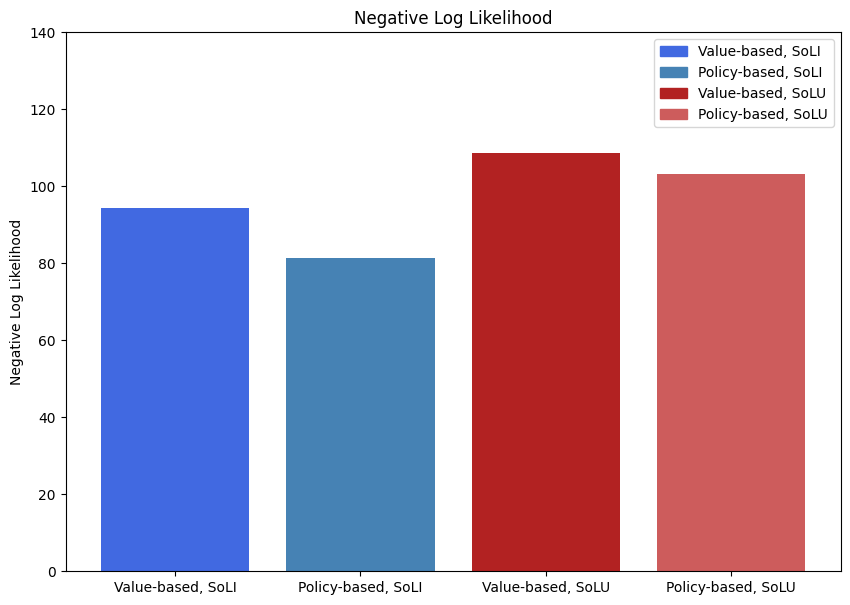

In [30]:
from matplotlib.patches import Patch


x = ['Value-based, SoLI', 'Policy-based, SoLI', 'Value-based, SoLU', 'Policy-based, SoLU']

mean_values = [np.mean(sorted_soli_cv_nll), np.mean(sorted_soli_tv_nll), np.mean(sorted_solu_cv_nll), np.mean(sorted_solu_tv_nll)]
clr = ['royalblue', 'steelblue', 'firebrick', 'indianred']
labels = ['Value-based, SoLI', 'Policy-based, SoLI', 'Value-based, SoLU', 'Policy-based, SoLU']
fig, axs = plt.subplots(1, 1, figsize=(10, 7))

axs.bar(x, mean_values, color=clr)
axs.set_ylim([0, 140])
axs.set_title('Negative Log Likelihood')
axs.set_ylabel('Negative Log Likelihood')
handles = [Patch(color=clr[i], label=labels[i]) for i in range(len(clr))]
axs.legend(handles=handles, loc='best')

alpha and beta corelations

Text(0.5, 1.0, 'Coefficient: 0.0388      P value: 0.8002')

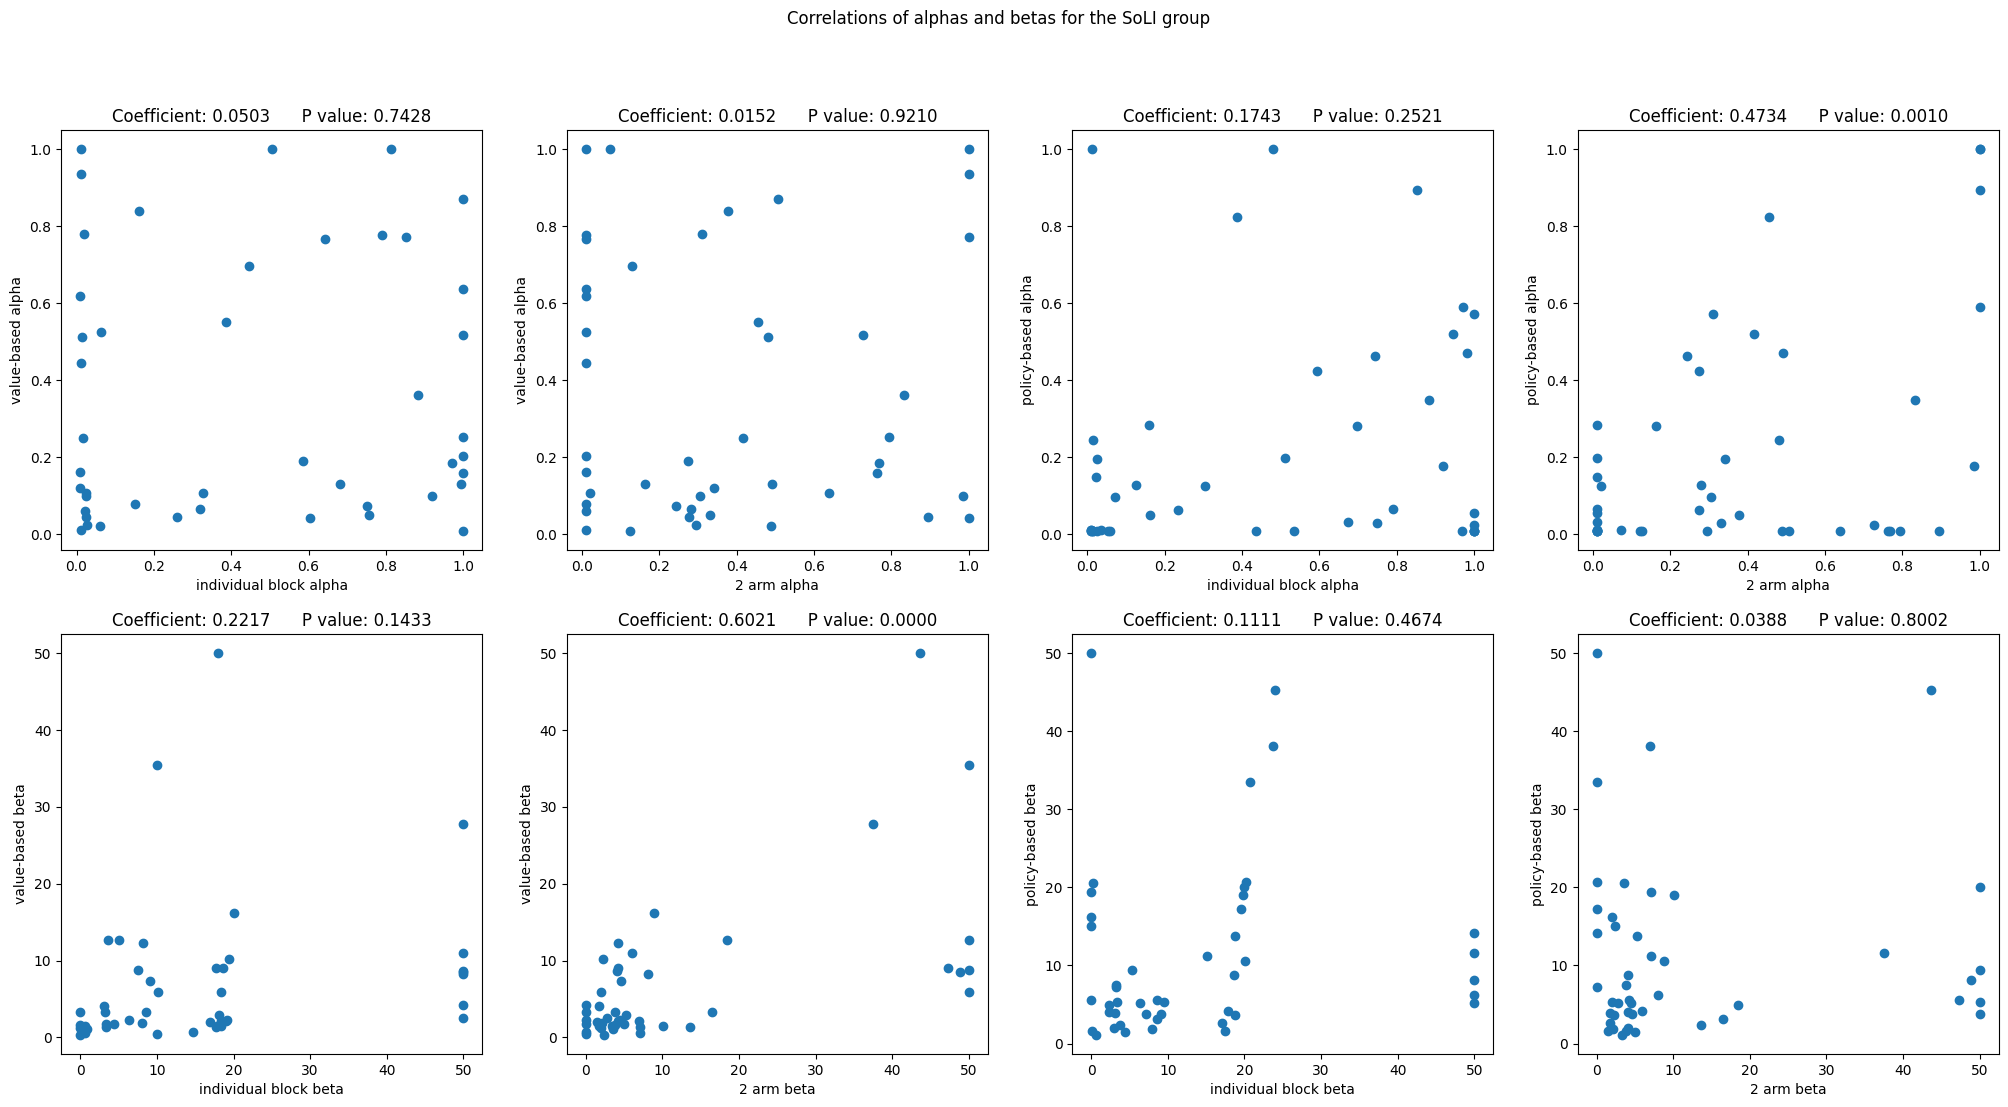

In [31]:
from scipy.stats import pearsonr

fig, axs = plt.subplots(2, 4, figsize=(25, 12))

fig.suptitle('Correlations of alphas and betas for the SoLI group')


r, p = pearsonr(sorted_soli_cv_alpha_ind, sorted_soli_cv_alpha)
axs[0, 0].scatter(sorted_soli_cv_alpha_ind,  sorted_soli_cv_alpha)
axs[0, 0].set_xlabel('individual block alpha')
axs[0, 0].set_ylabel('value-based alpha')
axs[0, 0].set_title('Coefficient: '+ format(r, ".4f") + '      P value: ' + format(p, ".4f"))

r, p = pearsonr(sorted_soli_2arm_alpha, sorted_soli_cv_alpha)
axs[0, 1].scatter(sorted_soli_2arm_alpha, sorted_soli_cv_alpha)
axs[0, 1].set_xlabel('2 arm alpha')
axs[0, 1].set_ylabel('value-based alpha')
axs[0, 1].set_title('Coefficient: '+ format(r, ".4f") + '      P value: ' + format(p, ".4f"))

r, p = pearsonr(sorted_soli_tv_alpha_ind, sorted_soli_tv_alpha)
axs[0, 2].scatter(sorted_soli_tv_alpha_ind,  sorted_soli_tv_alpha)
axs[0, 2].set_xlabel('individual block alpha')
axs[0, 2].set_ylabel('policy-based alpha')
axs[0, 2].set_title('Coefficient: '+ format(r, ".4f") + '      P value: ' + format(p, ".4f"))

r, p = pearsonr(sorted_soli_2arm_alpha, sorted_soli_tv_alpha)
axs[0, 3].scatter(sorted_soli_2arm_alpha, sorted_soli_tv_alpha)
axs[0, 3].set_xlabel('2 arm alpha')
axs[0, 3].set_ylabel('policy-based alpha')
axs[0, 3].set_title('Coefficient: '+ format(r, ".4f") + '      P value: ' + format(p, ".4f"))



r, p = pearsonr(sorted_soli_cv_beta_ind, sorted_soli_cv_beta)
axs[1, 0].scatter(sorted_soli_cv_beta_ind,  sorted_soli_cv_beta)
axs[1, 0].set_xlabel('individual block beta')
axs[1, 0].set_ylabel('value-based beta')
axs[1, 0].set_title('Coefficient: '+ format(r, ".4f") + '      P value: ' + format(p, ".4f"))

r, p = pearsonr(sorted_soli_2arm_beta, sorted_soli_cv_beta)
axs[1, 1].scatter(sorted_soli_2arm_beta, sorted_soli_cv_beta)
axs[1, 1].set_xlabel('2 arm beta')
axs[1, 1].set_ylabel('value-based beta')
axs[1, 1].set_title('Coefficient: '+ format(r, ".4f") + '      P value: ' + format(p, ".4f"))

r, p = pearsonr(sorted_soli_tv_beta_ind, sorted_soli_tv_beta)
axs[1, 2].scatter(sorted_soli_tv_beta_ind,  sorted_soli_tv_beta)
axs[1, 2].set_xlabel('individual block beta')
axs[1, 2].set_ylabel('policy-based beta')
axs[1, 2].set_title('Coefficient: '+ format(r, ".4f") + '      P value: ' + format(p, ".4f"))

r, p = pearsonr(sorted_soli_2arm_beta, sorted_soli_tv_beta)
axs[1, 3].scatter(sorted_soli_2arm_beta, sorted_soli_tv_beta)
axs[1, 3].set_xlabel('2 arm beta')
axs[1, 3].set_ylabel('policy-based beta')
axs[1, 3].set_title('Coefficient: '+ format(r, ".4f") + '      P value: ' + format(p, ".4f"))

Visualizing models parameters

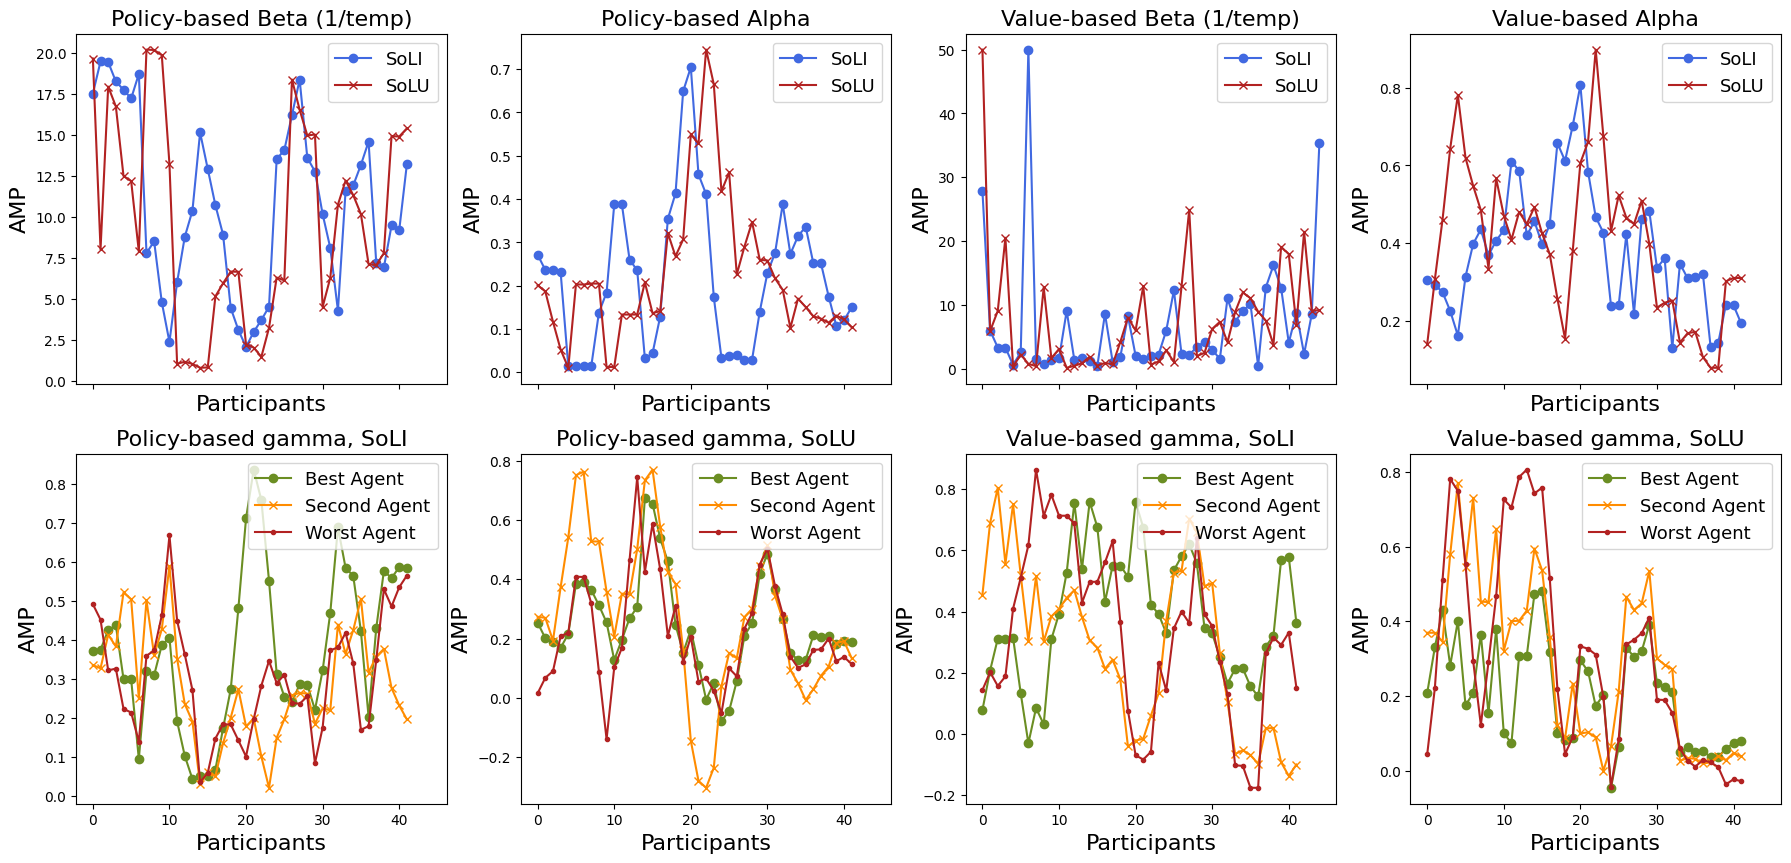

In [32]:
fig, axs = plt.subplots(2, 4, sharex='all', figsize=(22, 10))




x1 = [i for i in range(45)]
axs[0, 0].plot(np.convolve(sorted_soli_tv_beta, np.ones(4)/4, mode='valid'), marker='o', label='SoLI', color='royalblue')
axs[0, 0].plot(np.convolve(sorted_solu_tv_beta, np.ones(4)/4, mode='valid'), marker='x', label='SoLU', color='firebrick')
axs[0, 0].set_title('Policy-based Beta (1/temp)', fontsize=16)
axs[0, 0].set_xlabel('Participants', fontsize=16)
axs[0, 0].set_ylabel('AMP', fontsize=16)
axs[0, 0].legend(loc=0, prop={'size':13})

axs[0, 1].plot(np.convolve(sorted_soli_tv_alpha, np.ones(4)/4, mode='valid'), marker='o', label='SoLI', color='royalblue')
axs[0, 1].plot(np.convolve(sorted_solu_tv_alpha, np.ones(4)/4, mode='valid'), marker='x', label='SoLU', color='firebrick')
axs[0, 1].set_title('Policy-based Alpha', fontsize=16)
axs[0, 1].set_xlabel('Participants', fontsize=16)
axs[0, 1].set_ylabel('AMP', fontsize=16)
axs[0, 1].legend(loc=0, prop={'size':13})

axs[0, 2].plot(sorted_soli_cv_beta, marker='o', label='SoLI', color='royalblue')
axs[0, 2].plot(sorted_solu_cv_beta, marker='x', label='SoLU', color='firebrick')
axs[0, 2].set_title('Value-based Beta (1/temp)', fontsize=16)
axs[0, 2].set_xlabel('Participants', fontsize=16)
axs[0, 2].set_ylabel('AMP', fontsize=16)
axs[0, 2].legend(loc=0, prop={'size':13})

axs[0, 3].plot(np.convolve(sorted_soli_cv_alpha, np.ones(4)/4, mode='valid'), marker='o', label='SoLI', color='royalblue')
axs[0, 3].plot(np.convolve(sorted_solu_cv_alpha, np.ones(4)/4, mode='valid'), marker='x', label='SoLU', color='firebrick')
axs[0, 3].set_title('Value-based Alpha', fontsize=16)
axs[0, 3].set_xlabel('Participants', fontsize=16)
axs[0, 3].set_ylabel('AMP', fontsize=16)
axs[0, 3].legend(loc=0, prop={'size':13})

axs[1, 0].plot(np.convolve(sorted_soli_tv_gammas[:, 0], np.ones(4)/4, mode='valid'), marker='o', label='Best Agent', color='olivedrab')
axs[1, 0].plot(np.convolve(sorted_soli_tv_gammas[:, 1], np.ones(4)/4, mode='valid'), marker='x', label='Second Agent', color='darkorange')
axs[1, 0].plot(np.convolve(sorted_soli_tv_gammas[:, 2], np.ones(4)/4, mode='valid'), marker='.', label='Worst Agent', color='firebrick')
axs[1, 0].set_title('Policy-based gamma, SoLI', fontsize=16)
axs[1, 0].set_xlabel('Participants', fontsize=16)
axs[1, 0].set_ylabel('AMP', fontsize=16)
axs[1, 0].legend(loc=0, prop={'size':13})

axs[1, 1].plot(np.convolve(sorted_solu_tv_gammas[:, 0], np.ones(4)/4, mode='valid'), marker='o', label='Best Agent', color='olivedrab')
axs[1, 1].plot(np.convolve(sorted_solu_tv_gammas[:, 1], np.ones(4)/4, mode='valid'), marker='x', label='Second Agent', color='darkorange')
axs[1, 1].plot(np.convolve(sorted_solu_tv_gammas[:, 2], np.ones(4)/4, mode='valid'), marker='.', label='Worst Agent', color='firebrick')
axs[1, 1].set_title('Policy-based gamma, SoLU', fontsize=16)
axs[1, 1].set_xlabel('Participants', fontsize=16)
axs[1, 1].set_ylabel('AMP', fontsize=16)
axs[1, 1].legend(loc=0, prop={'size':13})

axs[1, 2].plot(np.convolve(sorted_soli_cv_gammas[:, 0], np.ones(4)/4, mode='valid'), marker='o', label='Best Agent', color='olivedrab')
axs[1, 2].plot(np.convolve(sorted_soli_cv_gammas[:, 1], np.ones(4)/4, mode='valid'), marker='x', label='Second Agent', color='darkorange')
axs[1, 2].plot(np.convolve(sorted_soli_cv_gammas[:, 2], np.ones(4)/4, mode='valid'), marker='.', label='Worst Agent', color='firebrick')
axs[1, 2].set_title('Value-based gamma, SoLI', fontsize=16)
axs[1, 2].set_xlabel('Participants', fontsize=16)
axs[1, 2].set_ylabel('AMP', fontsize=16)
axs[1, 2].legend(loc=0, prop={'size':13})

axs[1, 3].plot(np.convolve(sorted_solu_cv_gammas[:, 0], np.ones(4)/4, mode='valid'), marker='o', label='Best Agent', color='olivedrab')
axs[1, 3].plot(np.convolve(sorted_solu_cv_gammas[:, 1], np.ones(4)/4, mode='valid'), marker='x', label='Second Agent', color='darkorange')
axs[1, 3].plot(np.convolve(sorted_solu_cv_gammas[:, 2], np.ones(4)/4, mode='valid'), marker='.', label='Worst Agent', color='firebrick')
axs[1, 3].set_title('Value-based gamma, SoLU', fontsize=16)
axs[1, 3].set_xlabel('Participants', fontsize=16)
axs[1, 3].set_ylabel('AMP', fontsize=16)
axs[1, 3].legend(loc=0, prop={'size':13})


# fig.savefig('D:/University/University of Tehran/MSc/Thesis/paper draft/main/paper draft/Figures/newRL1.svg')

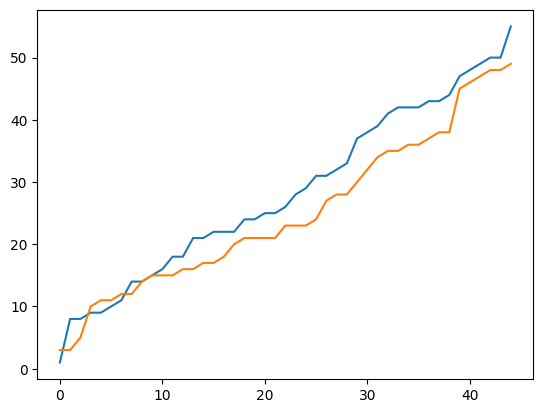

In [33]:
plt.plot(soli_sorted_perf)
plt.plot(solu_sorted_perf)

In [34]:
sorted_soli_cv_gammas[:45, 0]

array([ 4.87418901e-03,  2.29612231e-02,  9.03616899e-03,  2.75781034e-01,
        5.20830867e-01,  4.39504501e-01,  3.79575297e-04,  2.98655853e-01,
       -2.08970892e-01, -2.13474844e-01,  4.61813018e-01,  8.57239118e-02,
        9.04481772e-01,  1.20161403e-01,  1.00000000e+00,  1.00000000e+00,
        3.85058829e-02,  1.00000000e+00,  6.67994537e-01,  1.89422422e-02,
        5.15806125e-01,  1.00000000e+00,  5.20740657e-01,  1.00000000e+00,
        1.78829950e-01, -6.89802930e-03,  3.95067428e-01,  7.52872700e-01,
        1.00000000e+00,  1.76062838e-01,  5.55160554e-01,  4.99098476e-01,
        1.54765542e-01,  1.04663348e-01,  2.43446816e-01,  1.55994006e-01,
        3.47928432e-01,  1.08435433e-01,  9.72289705e-03,  2.37573174e-02,
        1.00000000e+00,  2.51009953e-01,  1.00000000e+00,  6.48282973e-02,
        1.33711012e-01])

# Simple RL

In [35]:
def Q_4arms(x, *args):
    alpha_ind, beta_ind, alpha, beta = x
    actions, rewards = args

    Q = np.zeros(4) * 0.5
    logp_actions = np.zeros(len(actions))

    for t, (a, r) in enumerate(zip(actions, rewards)):
        
        
        if t > 15:
            Q_ = Q * beta
            logp_action = Q_ - scipy.special.logsumexp(Q_)
            logp_actions[t] = logp_action[a]
            Q[a] = Q[a] + alpha * (r - Q[a])
        else:
            Q_ = Q * beta_ind
            logp_action = Q_ - scipy.special.logsumexp(Q_)
            logp_actions[t] = logp_action[a]
            Q[a] = Q[a] + alpha_ind * (r - Q[a])
    return -np.sum(logp_actions[1:])

In [36]:
import os
import scipy
all_soli_simple_alpha_ind = []
all_soli_simple_beta_ind = []
all_soli_simple_alpha = []
all_soli_simple_beta = []
all_soli_simple_neg_ll = []
for sub in all_trained_4arm_df:
  frame = sub
  actions = frame['choice'][:105]
  rewards = (frame['outcome'][:105] == 'win') * 1
  true_alpha = 0.2
  true_beta = 20
  x0 = [0.2, 20, true_alpha, true_beta]
  result = scipy.optimize.minimize(Q_4arms, x0, args=(actions, rewards), method="L-BFGS-B" ,bounds=((0.01, 1), (0.01, 50), (0.01, 1), (0.01, 50)))
  print(result)
  print("")
  print(f"MLE: alpha = {result.x[0]:.2f}")
  print(f"MLE: epsilon = {result.x[1]:.2f}")
  all_soli_simple_alpha_ind.append(result.x[0])
  all_soli_simple_beta_ind.append(result.x[1])
  all_soli_simple_alpha.append(result.x[2])
  all_soli_simple_beta.append(result.x[3])
  all_soli_simple_neg_ll.append(result.fun)

  message: CONVERGENCE: REL_REDUCTION_OF_F_<=_FACTR*EPSMCH
  success: True
   status: 0
      fun: 122.24151353576661
        x: [ 3.216e-02  2.076e+01  2.491e-02  3.470e+00]
      nit: 44
      jac: [ 1.214e-03  2.842e-06  2.132e-05 -2.842e-06]
     nfev: 265
     njev: 53
 hess_inv: <4x4 LbfgsInvHessProduct with dtype=float64>

MLE: alpha = 0.03
MLE: epsilon = 20.76
  message: CONVERGENCE: REL_REDUCTION_OF_F_<=_FACTR*EPSMCH
  success: True
   status: 0
      fun: 56.219982268349895
        x: [ 9.650e-01  5.000e+01  2.720e-01  6.510e+00]
      nit: 41
      jac: [-1.421e-06 -1.283e-03 -4.832e-05  1.421e-05]
     nfev: 245
     njev: 49
 hess_inv: <4x4 LbfgsInvHessProduct with dtype=float64>

MLE: alpha = 0.96
MLE: epsilon = 50.00
  message: CONVERGENCE: REL_REDUCTION_OF_F_<=_FACTR*EPSMCH
  success: True
   status: 0
      fun: 115.05334870647712
        x: [ 4.736e-02  1.364e+01  2.963e-01  3.735e+00]
      nit: 25
      jac: [-3.197e-04  0.000e+00  1.421e-04  4.263e-06]
     nfev: 1

In [37]:
import os
import scipy
all_solu_simple_alpha_ind = []
all_solu_simple_beta_ind = []
all_solu_simple_alpha = []
all_solu_simple_beta = []
all_solu_simple_neg_ll = []
for sub in all_not_trained_4arm_df:
  frame = sub
  actions = frame['choice'][:105]
  rewards = (frame['outcome'][:105] == 'win') * 1
  true_alpha = 0.2
  true_beta = 20
  x0 = [0.2, 20, true_alpha, true_beta]
  result = scipy.optimize.minimize(Q_4arms, x0, args=(actions, rewards), method="L-BFGS-B" ,bounds=((0.01, 1), (0.01, 50), (0.01, 1), (0.01, 50)))
  print(result)
  print("")
  print(f"MLE: alpha = {result.x[0]:.2f}")
  print(f"MLE: epsilon = {result.x[1]:.2f}")
  all_solu_simple_alpha_ind.append(result.x[0])
  all_solu_simple_beta_ind.append(result.x[1])
  all_solu_simple_alpha.append(result.x[2])
  all_solu_simple_beta.append(result.x[3])
  all_solu_simple_neg_ll.append(result.fun)

  message: CONVERGENCE: REL_REDUCTION_OF_F_<=_FACTR*EPSMCH
  success: True
   status: 0
      fun: 145.1095652478107
        x: [ 1.000e-02  1.750e+01  1.000e-02  1.000e-02]
      nit: 3
      jac: [ 9.888e+01  5.677e-02  2.475e-01  2.937e-01]
     nfev: 25
     njev: 5
 hess_inv: <4x4 LbfgsInvHessProduct with dtype=float64>

MLE: alpha = 0.01
MLE: epsilon = 17.50
  message: CONVERGENCE: NORM_OF_PROJECTED_GRADIENT_<=_PGTOL
  success: True
   status: 0
      fun: 142.5590361412295
        x: [ 8.085e-01  1.236e+00  1.000e-02  1.000e-02]
      nit: 21
      jac: [-5.684e-06 -2.842e-06  3.099e-02  4.255e-01]
     nfev: 170
     njev: 34
 hess_inv: <4x4 LbfgsInvHessProduct with dtype=float64>

MLE: alpha = 0.81
MLE: epsilon = 1.24
  message: CONVERGENCE: NORM_OF_PROJECTED_GRADIENT_<=_PGTOL
  success: True
   status: 0
      fun: 138.50021677773526
        x: [ 1.000e-02  1.000e-02  8.597e-01  1.091e+00]
      nit: 30
      jac: [ 1.106e+01  3.974e-02  0.000e+00  0.000e+00]
     nfev: 175
 

# Visualization

## AIC

SoLI

In [38]:
all_soli_simple_neg_ll = np.array(all_soli_simple_neg_ll)

all_soli_simple_aic = 2 * 4 + 2 * all_soli_simple_neg_ll
all_soli_cv_aic = 2 * 7 + 2 * soli_cv_nll
all_soli_tv_aic = 2 * 7 + 2 * soli_tv_nll

SoLU

In [39]:
all_solu_simple_neg_ll = np.array(all_solu_simple_neg_ll)

all_solu_simple_aic = 2 * 4 + 2 * all_solu_simple_neg_ll
all_solu_cv_aic = 2 * 7 + 2 * solu_cv_nll
all_solu_tv_aic = 2 * 7 + 2 * solu_tv_nll

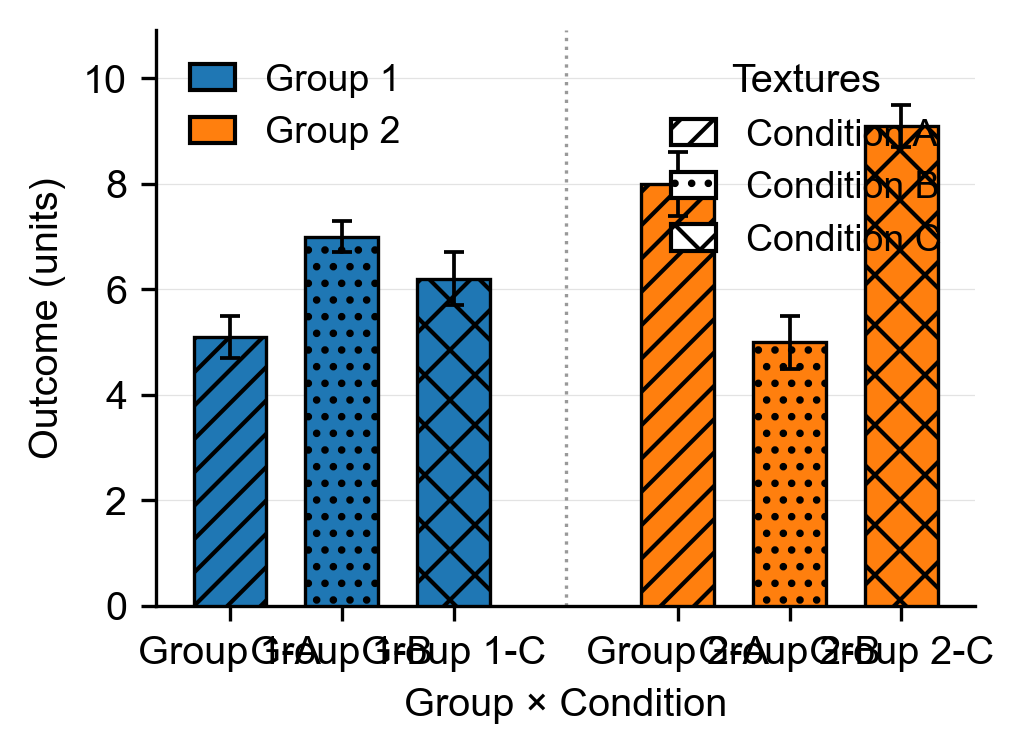

In [40]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Patch

# --------------------
# Example data (replace with yours)
# --------------------
group_names   = ["Group 1", "Group 2"]
condition_lbl = ["A", "B", "C"]
vals_g1 = np.array([5.1, 7.0, 6.2])
vals_g2 = np.array([8.0, 5.0, 9.1])
err_g1  = np.array([0.4, 0.3, 0.5])
err_g2  = np.array([0.6, 0.5, 0.4])

# --------------------
# Layout
# --------------------
n = len(condition_lbl)
gap = 1.0          # space between groups
w = 0.65           # bar width
x1 = np.arange(n)
x2 = x1 + n + gap

# Publication-friendly hatch patterns
HATCHES = ['///', '...', 'xx']   # diagonal lines, dots, cross-hatch

# --------------------
# Style (Nature-style)
# --------------------
plt.rcParams.update({
    "figure.dpi": 300,
    "font.size": 9.5,
    "font.family": "sans-serif",
    "font.sans-serif": ["Arial", "Helvetica", "DejaVu Sans"],
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.linewidth": 0.8,
    "xtick.major.width": 0.8,
    "ytick.major.width": 0.8,
})

# ~89 mm wide (single-column figure size)
fig = plt.figure(figsize=(3.5, 2.6))
ax = plt.gca()

# --------------------
# Bars
# --------------------
bars1 = ax.bar(x1, vals_g1, width=w, edgecolor="black", linewidth=0.8, zorder=3)
bars2 = ax.bar(x2, vals_g2, width=w, edgecolor="black", linewidth=0.8, zorder=3)

# Apply hatches for each condition
for i, b in enumerate(bars1): b.set_hatch(HATCHES[i])
for i, b in enumerate(bars2): b.set_hatch(HATCHES[i])

# Error bars
ax.errorbar(x1, vals_g1, yerr=err_g1, fmt="none", color="black",
            elinewidth=0.9, capsize=2.5, capthick=0.9, zorder=4)
ax.errorbar(x2, vals_g2, yerr=err_g2, fmt="none", color="black",
            elinewidth=0.9, capsize=2.5, capthick=0.9, zorder=4)

# --------------------
# Axes & labels
# --------------------
xticks = list(x1) + list(x2)
ax.set_xticks(xticks)
ax.set_xticklabels(
    [f"{group_names[0]}-{c}" for c in condition_lbl] +
    [f"{group_names[1]}-{c}" for c in condition_lbl]
)
ax.set_ylabel("Outcome (units)")
ax.set_xlabel("Group × Condition")

# Subtle grid and group separator
ax.grid(axis="y", linewidth=0.3, alpha=0.35, zorder=0)
ax.axvline((x1[-1] + x2[0]) / 2, linestyle=":", linewidth=0.8,
           color="black", alpha=0.4)

# Y-axis limit with headroom
ymax = np.max(np.r_[vals_g1+err_g1, vals_g2+err_g2])
ax.set_ylim(0, ymax * 1.15)

# --------------------
# Legends
# --------------------
c1, c2 = bars1[0].get_facecolor(), bars2[0].get_facecolor()
leg_groups = [Patch(facecolor=c1, edgecolor="black", label=group_names[0]),
              Patch(facecolor=c2, edgecolor="black", label=group_names[1])]
leg_tex = [Patch(facecolor="white", edgecolor="black", hatch=h, label=f"Condition {c}")
           for h, c in zip(HATCHES, condition_lbl)]

g1 = ax.legend(handles=leg_groups, loc="upper left", frameon=False,
               fontsize=9, handlelength=1.2)
g2 = ax.legend(handles=leg_tex, loc="upper right", frameon=False,
               fontsize=9, handlelength=1.2, title="Textures")
ax.add_artist(g1)

fig.tight_layout()

# --------------------
# Save outputs
# --------------------
fig.savefig("nhb_grouped_bars.png", dpi=600)  # high-res PNG
fig.savefig("nhb_grouped_bars.pdf")           # vector PDF
plt.show()

C:\Users\AsusIran\AppData\Local\Temp\ipykernel_6052\1576952960.py:39: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axs.set_xticklabels(x, rotation=45, ha="right", fontsize=fnt_size)


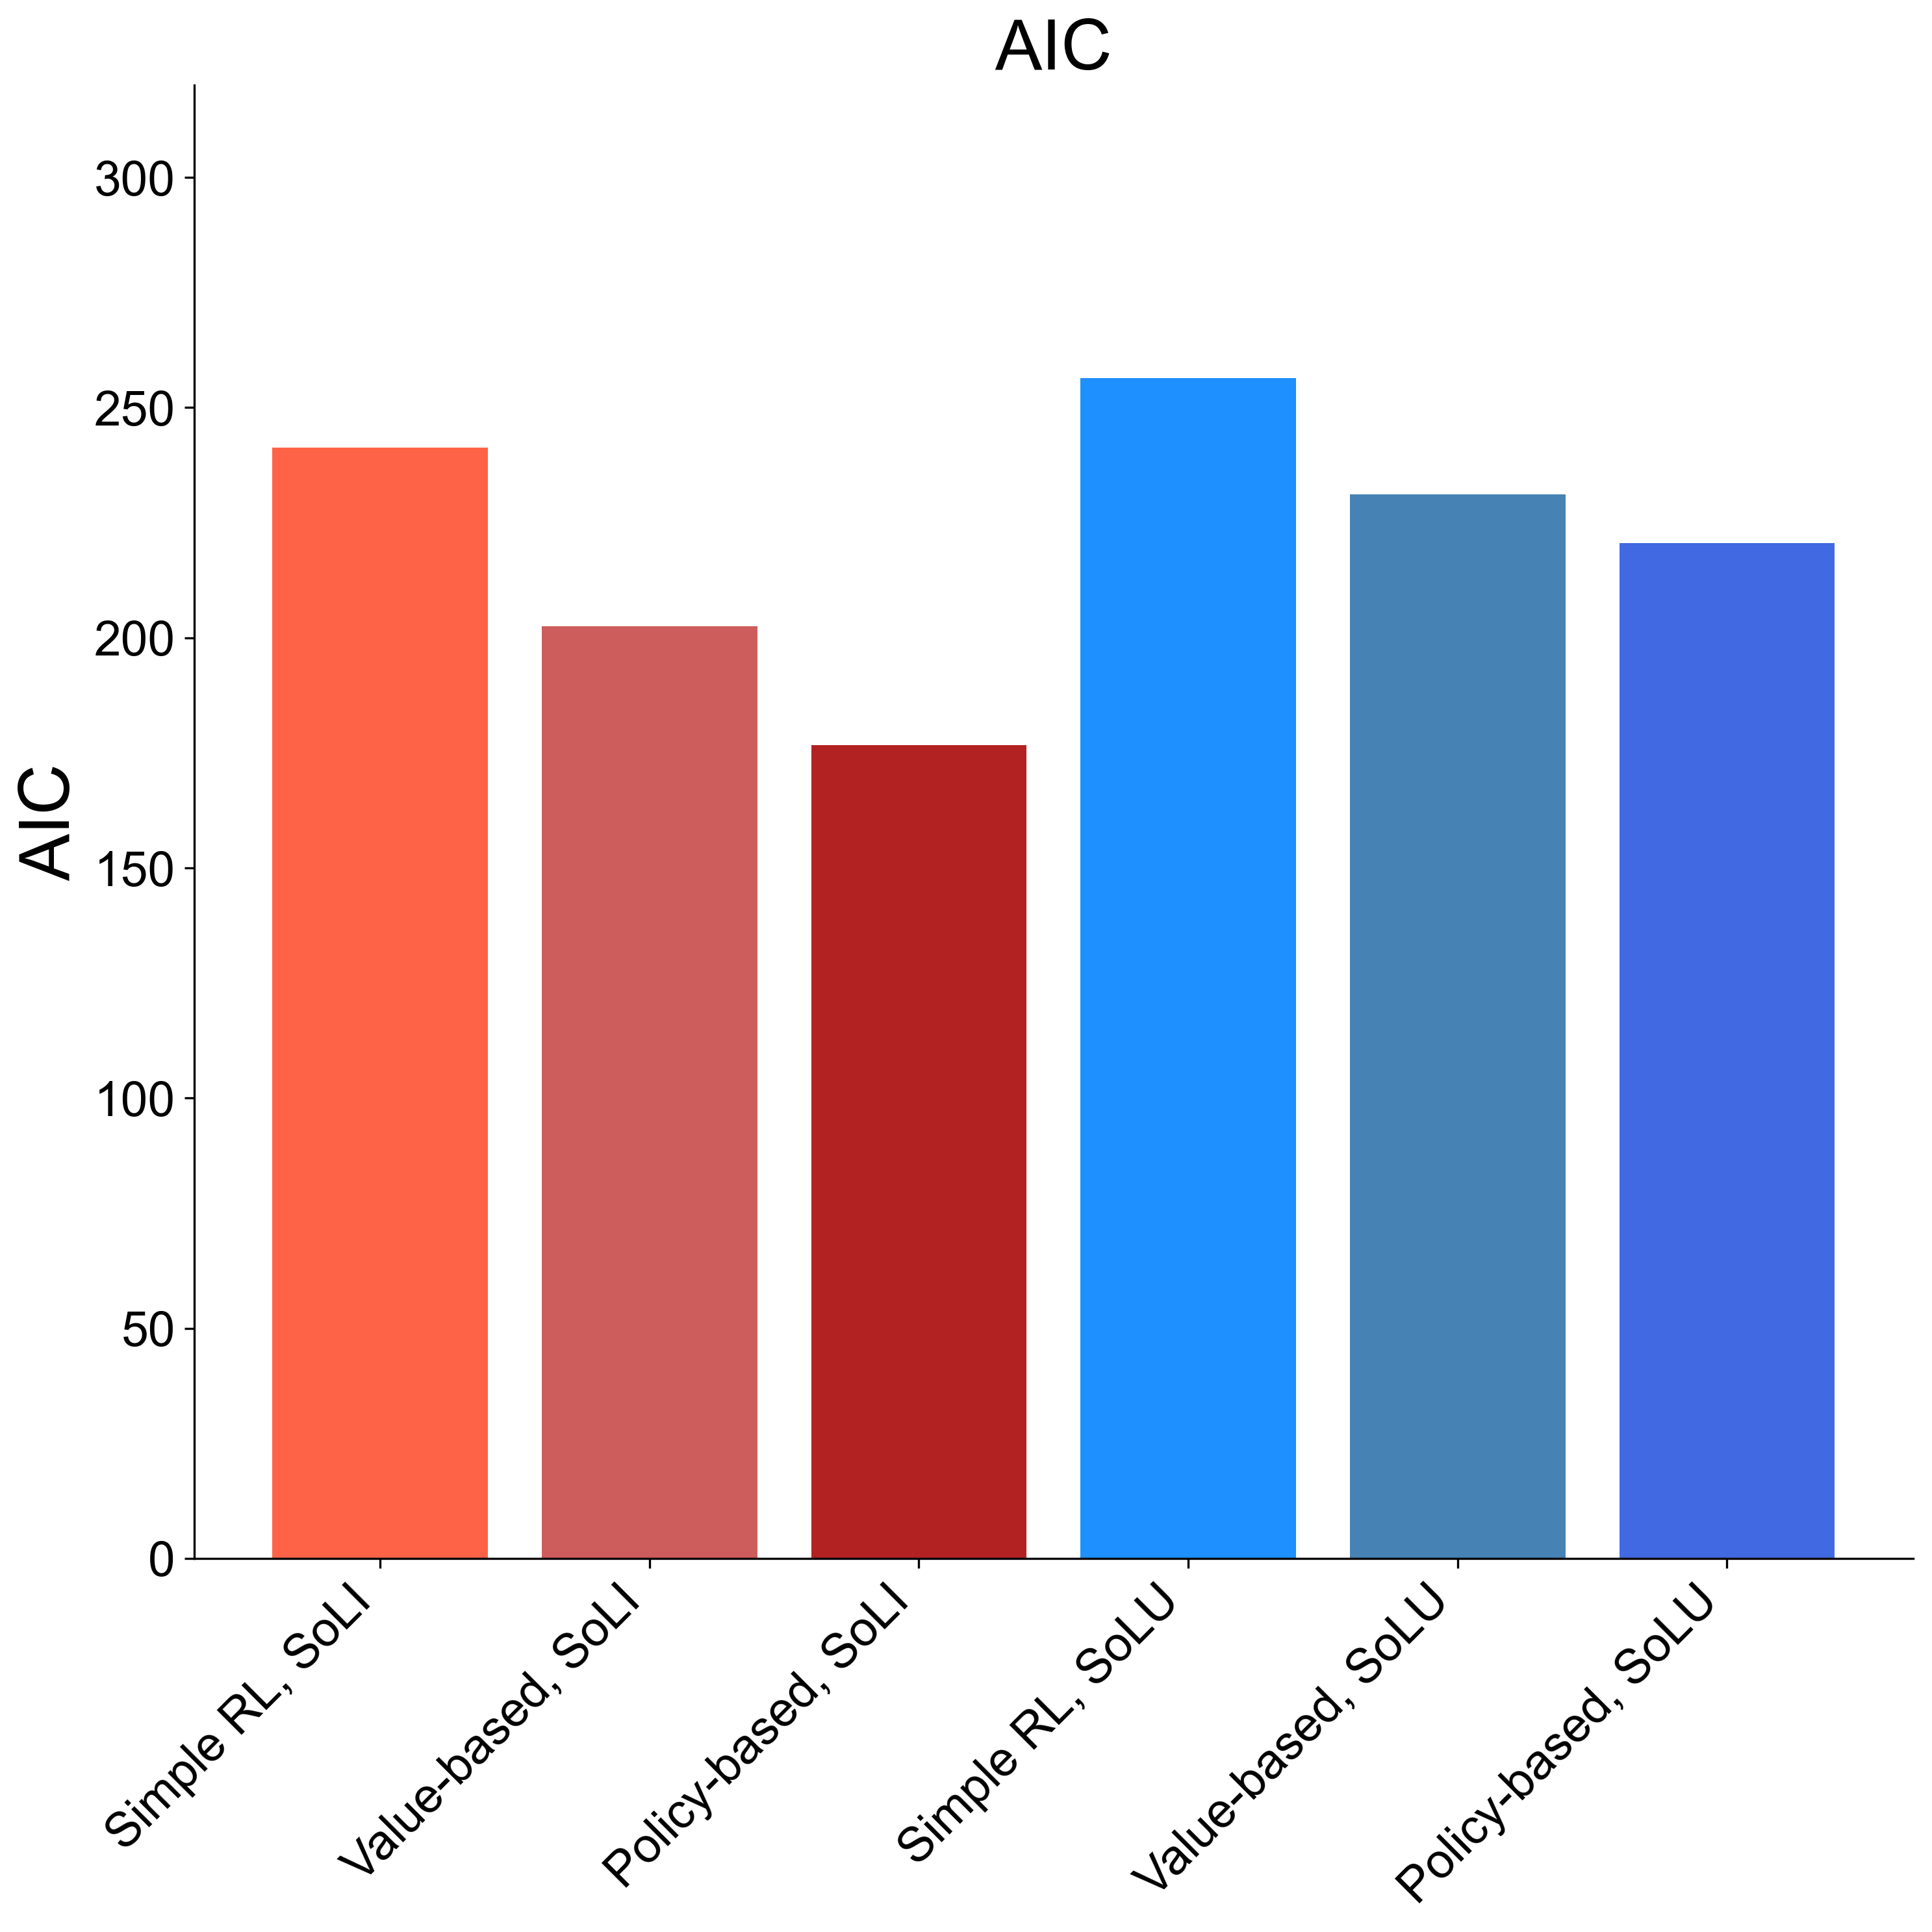

In [54]:
from matplotlib.patches import Patch


import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Patch

x = ['Simple RL, SoLI', 'Value-based, SoLI', 'Policy-based, SoLI',
     'Simple RL, SoLU', 'Value-based, SoLU', 'Policy-based, SoLU']

fnt_size = 26
lbl_size = 26

mean_values = [
    np.mean(all_soli_simple_aic),
    np.mean(all_soli_cv_aic),
    np.mean(all_soli_tv_aic),
    np.mean(all_solu_simple_aic),
    np.mean(all_solu_cv_aic),
    np.mean(all_solu_tv_aic)
]

clr = ['tomato', 'indianred', 'firebrick',
       'dodgerblue', 'steelblue', 'royalblue']
labels = x  # same list

fig, axs = plt.subplots(1, 1, figsize=(10, 10))

axs.bar(x, mean_values, color=clr)
axs.set_ylim([0, 320])

# bigger title
axs.set_title('AIC', fontsize=fnt_size)

# bigger y label
axs.set_ylabel('AIC', fontsize=fnt_size)

# bigger x tick labels
axs.set_xticklabels(x, rotation=45, ha="right", fontsize=fnt_size)

# bigger tick numbers (both axes)
axs.tick_params(axis='both', which='major', labelsize=18)

# legend with bigger font
handles = [Patch(color=clr[i], label=labels[i]) for i in range(len(clr))]
# axs.legend(handles=handles, loc='best', fontsize=12, title='Models', title_fontsize=13)

plt.tight_layout()

fig.savefig('D:/University/University of Tehran/MSc/Thesis/paper draft/main/paper draft/Figures/AIC.svg', bbox_inches='tight', pad_inches=0.02)

In [42]:
from scipy.stats import ttest_ind

# mean_values = [np.mean(all_soli_simple_aic), np.mean(all_soli_cv_aic), np.mean(all_soli_tv_aic), np.mean(all_solu_simple_aic), np.mean(all_solu_cv_aic), np.mean(all_solu_tv_aic)]

t_stat, p_value = ttest_ind(all_soli_simple_aic, all_soli_cv_aic)
print('Simple RL, SoLI VS Value-based, SoLI. t stat: ', t_stat, ' P value:', p_value)
t_stat, p_value = ttest_ind(all_soli_simple_aic, all_soli_tv_aic)
print('Simple RL, SoLI VS Policy-based, SoLI. t stat: ', t_stat, ' P value:', p_value)

t_stat, p_value = ttest_ind(all_soli_cv_aic, all_soli_tv_aic)
print('Value-based, SoLI VS Policy-based, SoLI. t stat: ', t_stat, ' P value:', p_value)

t_stat, p_value = ttest_ind(all_solu_simple_aic, all_solu_cv_aic)
print('Simple RL, SoLU VS Value-based, SoLU. t stat: ', t_stat, ' P value:', p_value)
t_stat, p_value = ttest_ind(all_solu_simple_aic, all_solu_tv_aic)
print('Simple RL, SoLU VS Policy-based, SoLU. t stat: ', t_stat, ' P value:', p_value)

t_stat, p_value = ttest_ind(all_solu_cv_aic, all_solu_tv_aic)
print('Value-based, SoLU VS Policy-based, SoLU. t stat: ', t_stat, ' P value:', p_value)

Simple RL, SoLI VS Value-based, SoLI. t stat:  3.722648410132372  P value: 0.00034709276983800196
Simple RL, SoLI VS Policy-based, SoLI. t stat:  5.3711655468237955  P value: 6.3126958300951e-07
Value-based, SoLI VS Policy-based, SoLI. t stat:  2.015121924368312  P value: 0.04694367992948746
Simple RL, SoLU VS Value-based, SoLU. t stat:  2.430023368359311  P value: 0.017128806304799314
Simple RL, SoLU VS Policy-based, SoLU. t stat:  3.040183175265198  P value: 0.003113955471984417
Value-based, SoLU VS Policy-based, SoLU. t stat:  0.7766013209639261  P value: 0.43947647617852204


## Diff NLL

In [55]:
def sort_with_indices(a):
    idx = np.argsort(a)
    return idx, a[idx]

In [56]:
soli_diff_idx, soli_sorted_diff_nll = sort_with_indices(soli_tv_nll - soli_cv_nll)
solu_diff_idx, solu_sorted_diff_nll = sort_with_indices(solu_tv_nll - solu_cv_nll)


In [57]:
soli_pv_diff_alpha = soli_tv_alpha[soli_diff_idx] - soli_cv_alpha[soli_diff_idx]
soli_pi_diff_alpha = soli_tv_alpha[soli_diff_idx] - soli_tv_alpha_ind[soli_diff_idx]
soli_vi_diff_alpha = soli_cv_alpha[soli_diff_idx] - soli_cv_alpha_ind[soli_diff_idx]

solu_pv_diff_alpha = solu_tv_alpha[soli_diff_idx] - solu_cv_alpha[soli_diff_idx]
solu_pi_diff_alpha = solu_tv_alpha[soli_diff_idx] - solu_tv_alpha_ind[soli_diff_idx]
solu_vi_diff_alpha = solu_cv_alpha[soli_diff_idx] - solu_cv_alpha_ind[soli_diff_idx]

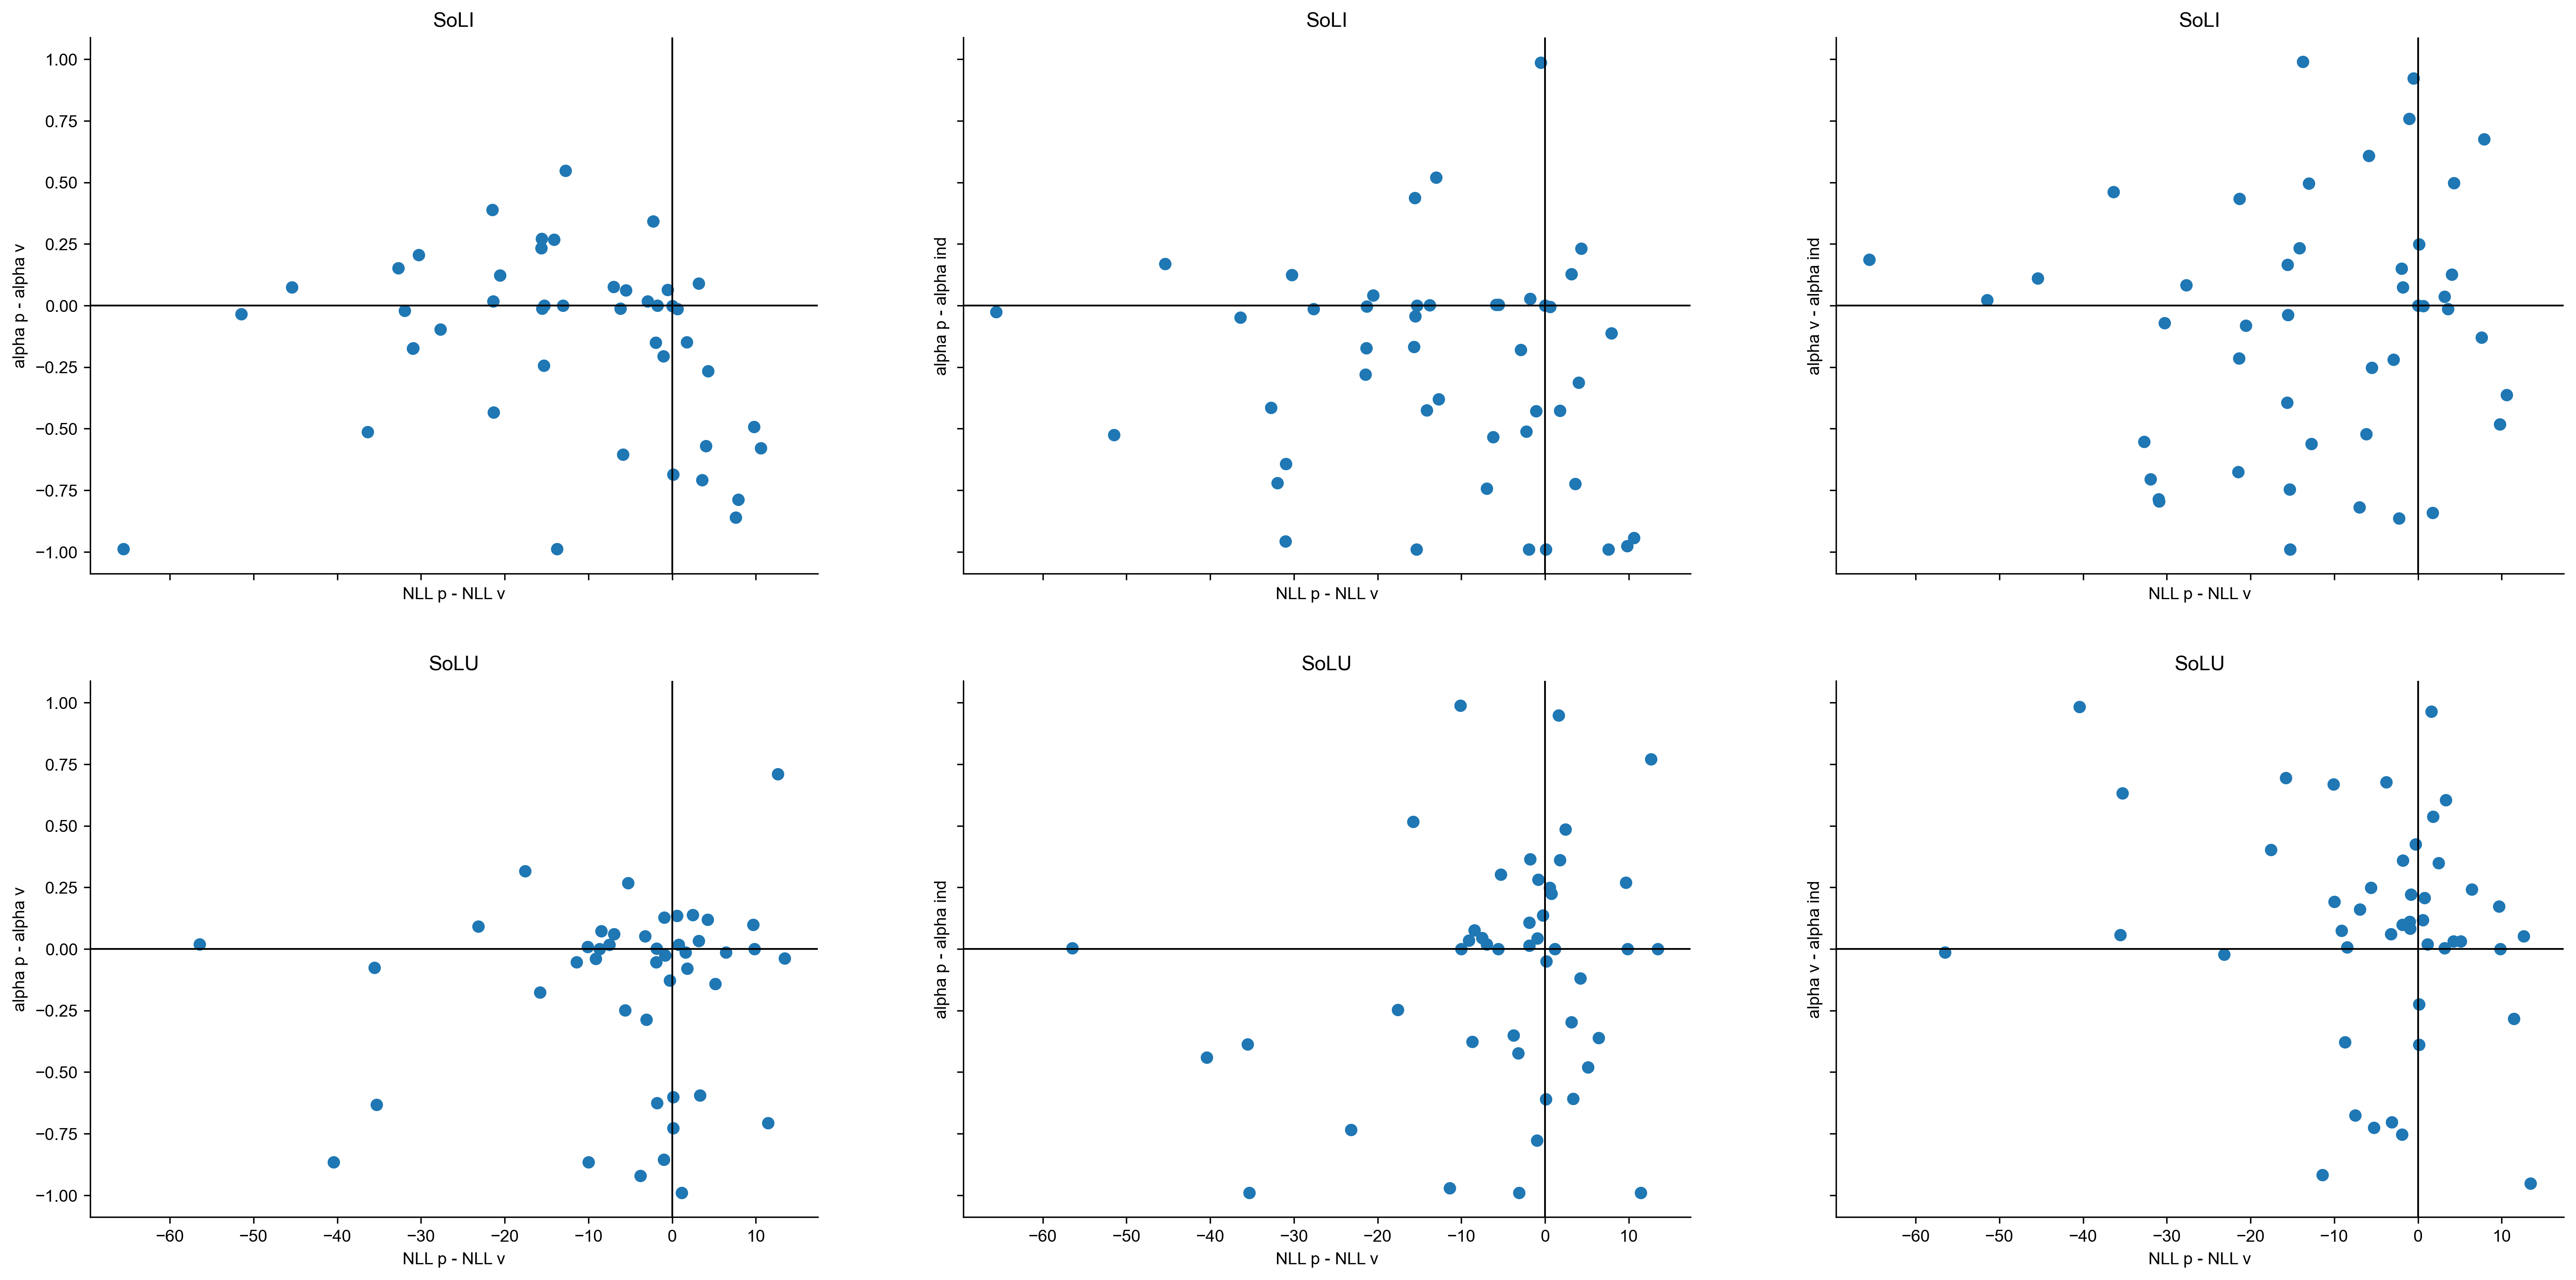

In [58]:
fig, axs = plt.subplots(2, 3, figsize=(25, 12), sharex=True, sharey=True)

# fig.suptitle('Correlations of alphas and betas for the SoLI group')

axs[0, 0].scatter(soli_sorted_diff_nll, soli_pv_diff_alpha)
axs[0, 0].set_xlabel('NLL p - NLL v')
axs[0, 0].set_ylabel('alpha p - alpha v')
axs[0, 0].axhline(0, color='black', linewidth=1)
axs[0, 0].axvline(0, color='black', linewidth=1)
axs[0, 0].set_title('SoLI')

axs[0, 1].scatter(soli_sorted_diff_nll, soli_pi_diff_alpha)
axs[0, 1].set_xlabel('NLL p - NLL v')
axs[0, 1].set_ylabel('alpha p - alpha ind')
axs[0, 1].axhline(0, color='black', linewidth=1)
axs[0, 1].axvline(0, color='black', linewidth=1)
axs[0, 1].set_title('SoLI')

axs[0, 2].scatter(soli_sorted_diff_nll, soli_vi_diff_alpha)
axs[0, 2].set_xlabel('NLL p - NLL v')
axs[0, 2].set_ylabel('alpha v - alpha ind')
axs[0, 2].axhline(0, color='black', linewidth=1)
axs[0, 2].axvline(0, color='black', linewidth=1)
axs[0, 2].set_title('SoLI')


axs[1, 0].scatter(solu_sorted_diff_nll, solu_pv_diff_alpha)
axs[1, 0].set_xlabel('NLL p - NLL v')
axs[1, 0].set_ylabel('alpha p - alpha v')
axs[1, 0].axhline(0, color='black', linewidth=1)
axs[1, 0].axvline(0, color='black', linewidth=1)
axs[1, 0].set_title('SoLU')

axs[1, 1].scatter(solu_sorted_diff_nll, solu_pi_diff_alpha)
axs[1, 1].set_xlabel('NLL p - NLL v')
axs[1, 1].set_ylabel('alpha p - alpha ind')
axs[1, 1].axhline(0, color='black', linewidth=1)
axs[1, 1].axvline(0, color='black', linewidth=1)
axs[1, 1].set_title('SoLU')

axs[1, 2].scatter(solu_sorted_diff_nll, solu_vi_diff_alpha)
axs[1, 2].set_xlabel('NLL p - NLL v')
axs[1, 2].set_ylabel('alpha v - alpha ind')
axs[1, 2].axhline(0, color='black', linewidth=1)
axs[1, 2].axvline(0, color='black', linewidth=1)
axs[1, 2].set_title('SoLU');





Text(0.5, 1.0, 'SoLU')

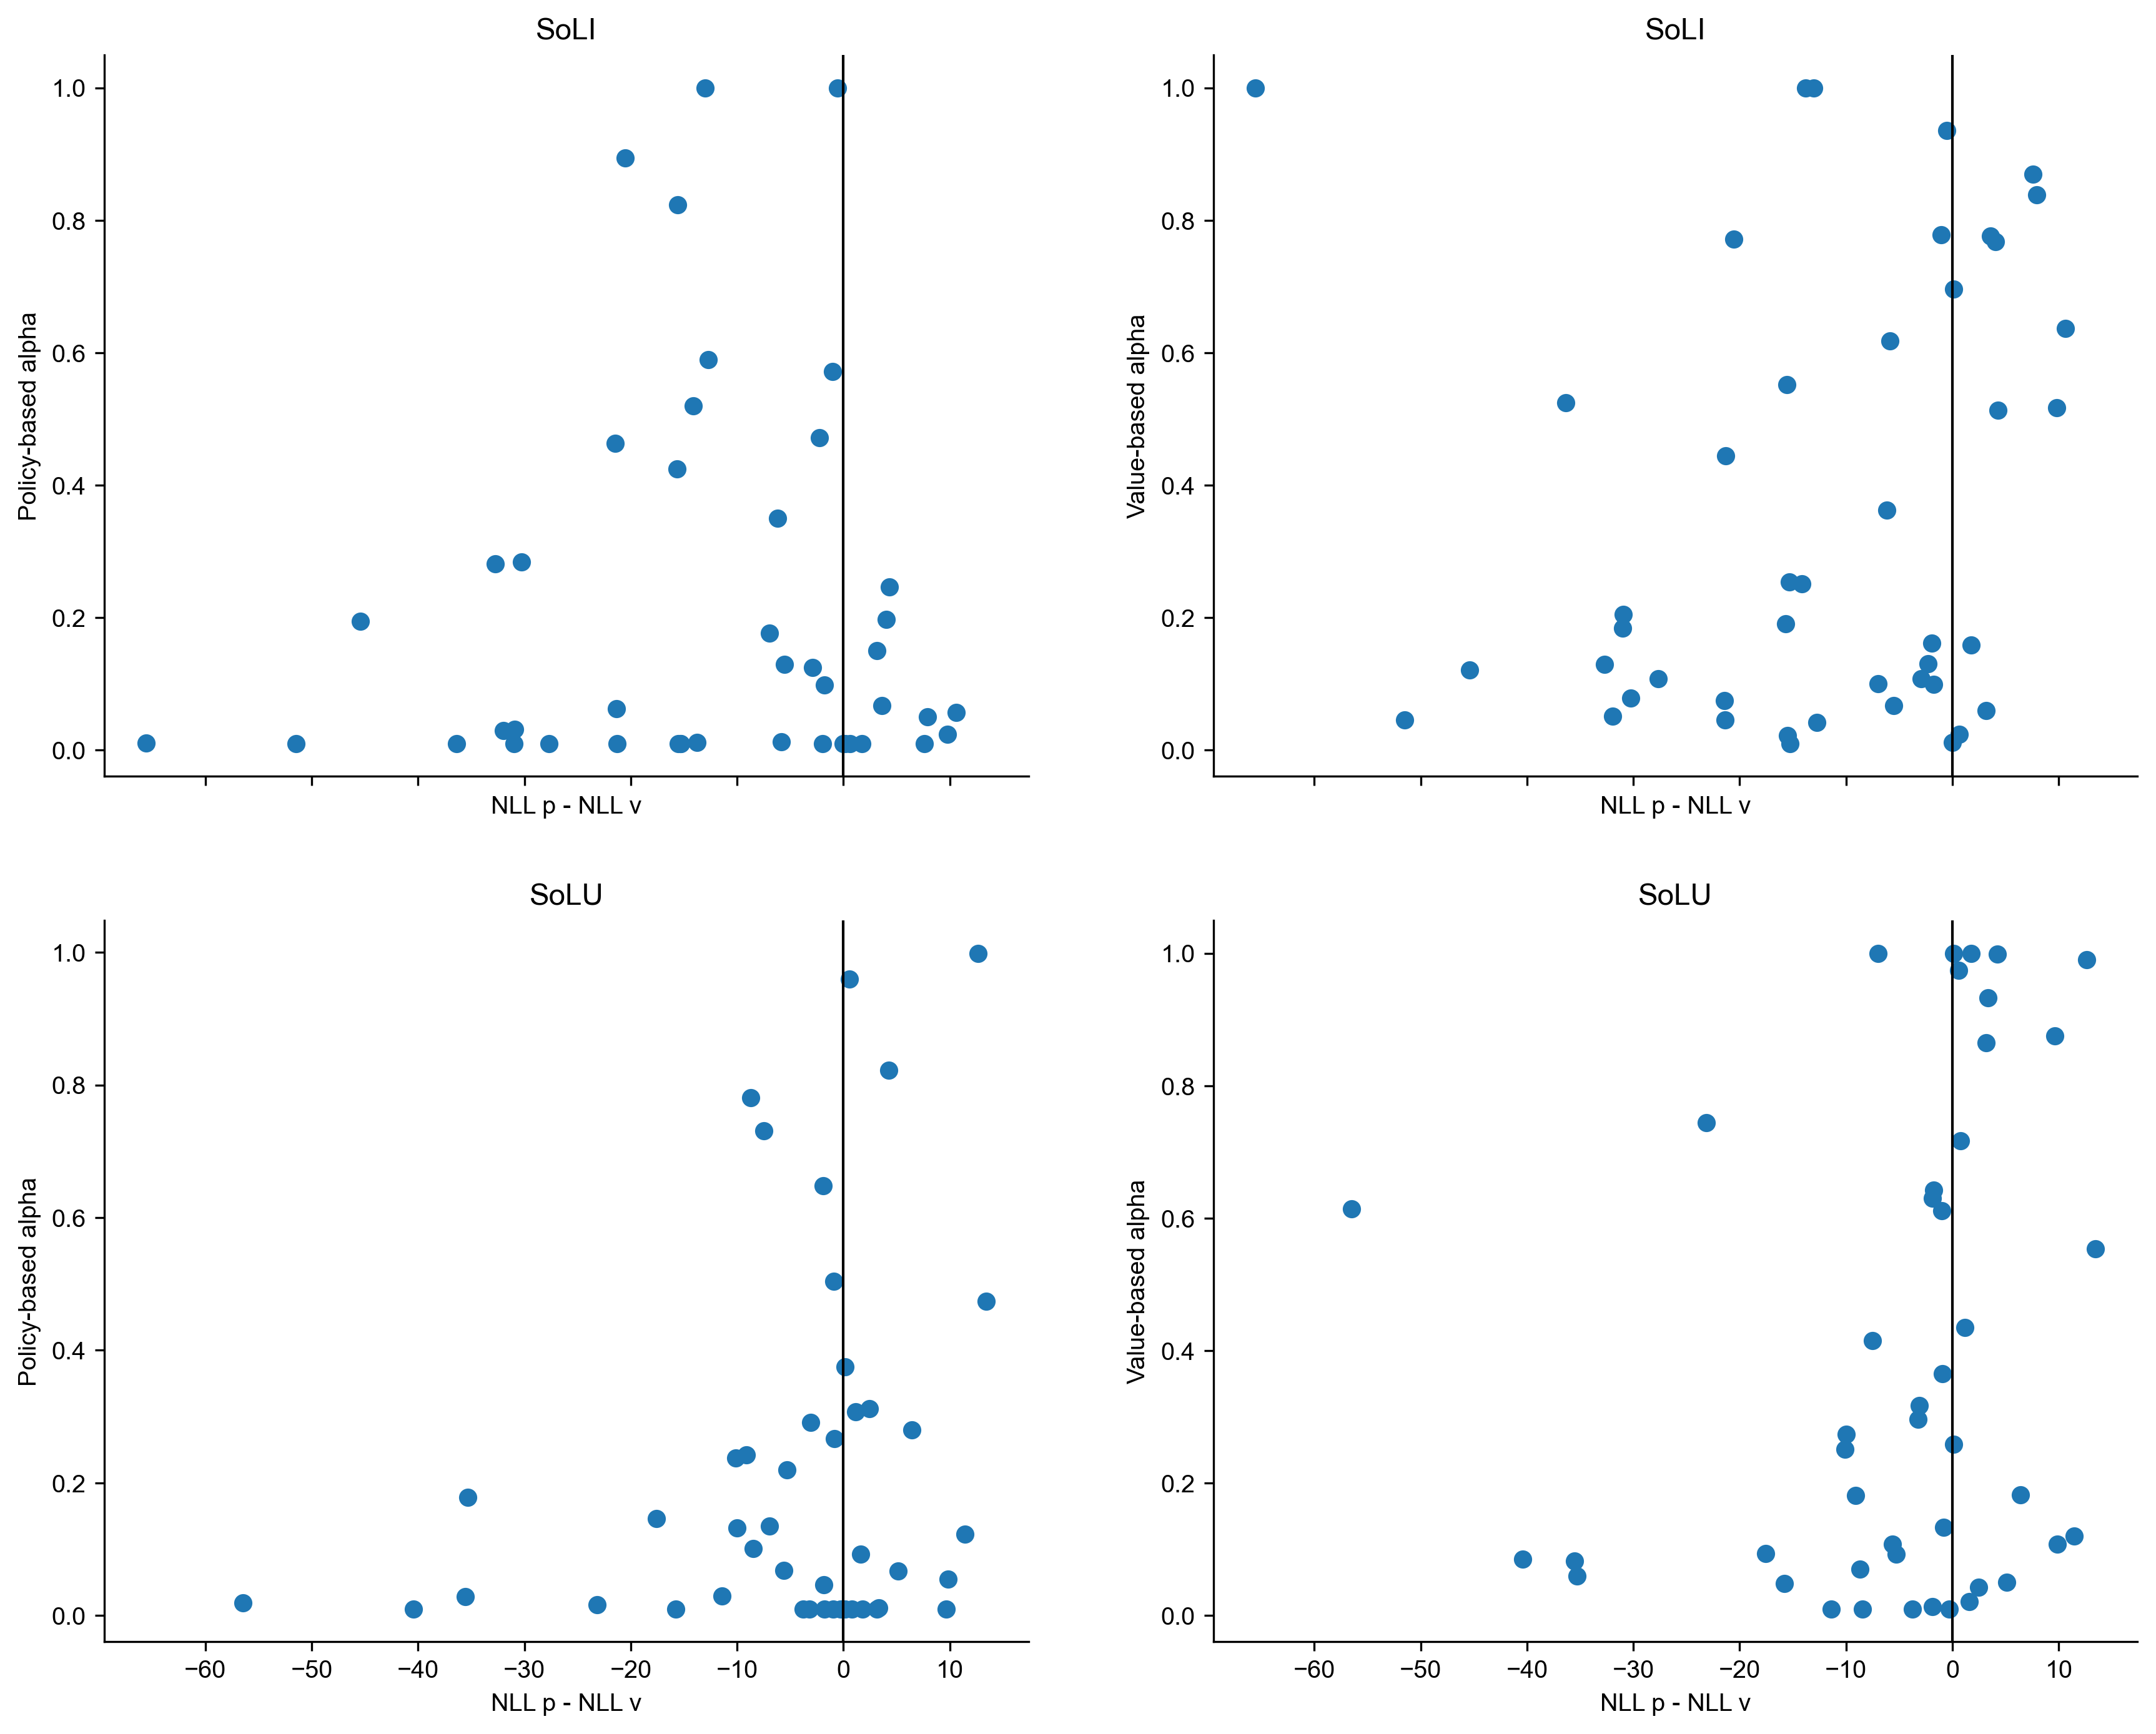

In [59]:
fig, axs = plt.subplots(2, 2, figsize=(14, 11), sharex=True)


# soli_tv_alpha[soli_diff_idx] - soli_cv_alpha[soli_diff_idx]


axs[0, 0].scatter(soli_sorted_diff_nll, soli_tv_alpha[soli_diff_idx])
axs[0, 0].axvline(0, color='black', linewidth=1)
axs[0, 0].set_xlabel('NLL p - NLL v')
axs[0, 0].set_ylabel('Policy-based alpha')
axs[0, 0].set_title('SoLI')

axs[0, 1].scatter(soli_sorted_diff_nll, soli_cv_alpha[soli_diff_idx])
axs[0, 1].axvline(0, color='black', linewidth=1)
axs[0, 1].set_xlabel('NLL p - NLL v')
axs[0, 1].set_ylabel('Value-based alpha')
axs[0, 1].set_title('SoLI')


axs[1, 0].scatter(solu_sorted_diff_nll, solu_tv_alpha[solu_diff_idx])
axs[1, 0].axvline(0, color='black', linewidth=1)
axs[1, 0].set_xlabel('NLL p - NLL v')
axs[1, 0].set_ylabel('Policy-based alpha')
axs[1, 0].set_title('SoLU')

axs[1, 1].scatter(solu_sorted_diff_nll, solu_cv_alpha[solu_diff_idx])
axs[1, 1].axvline(0, color='black', linewidth=1)
axs[1, 1].set_xlabel('NLL p - NLL v')
axs[1, 1].set_ylabel('Value-based alpha')
axs[1, 1].set_title('SoLU')

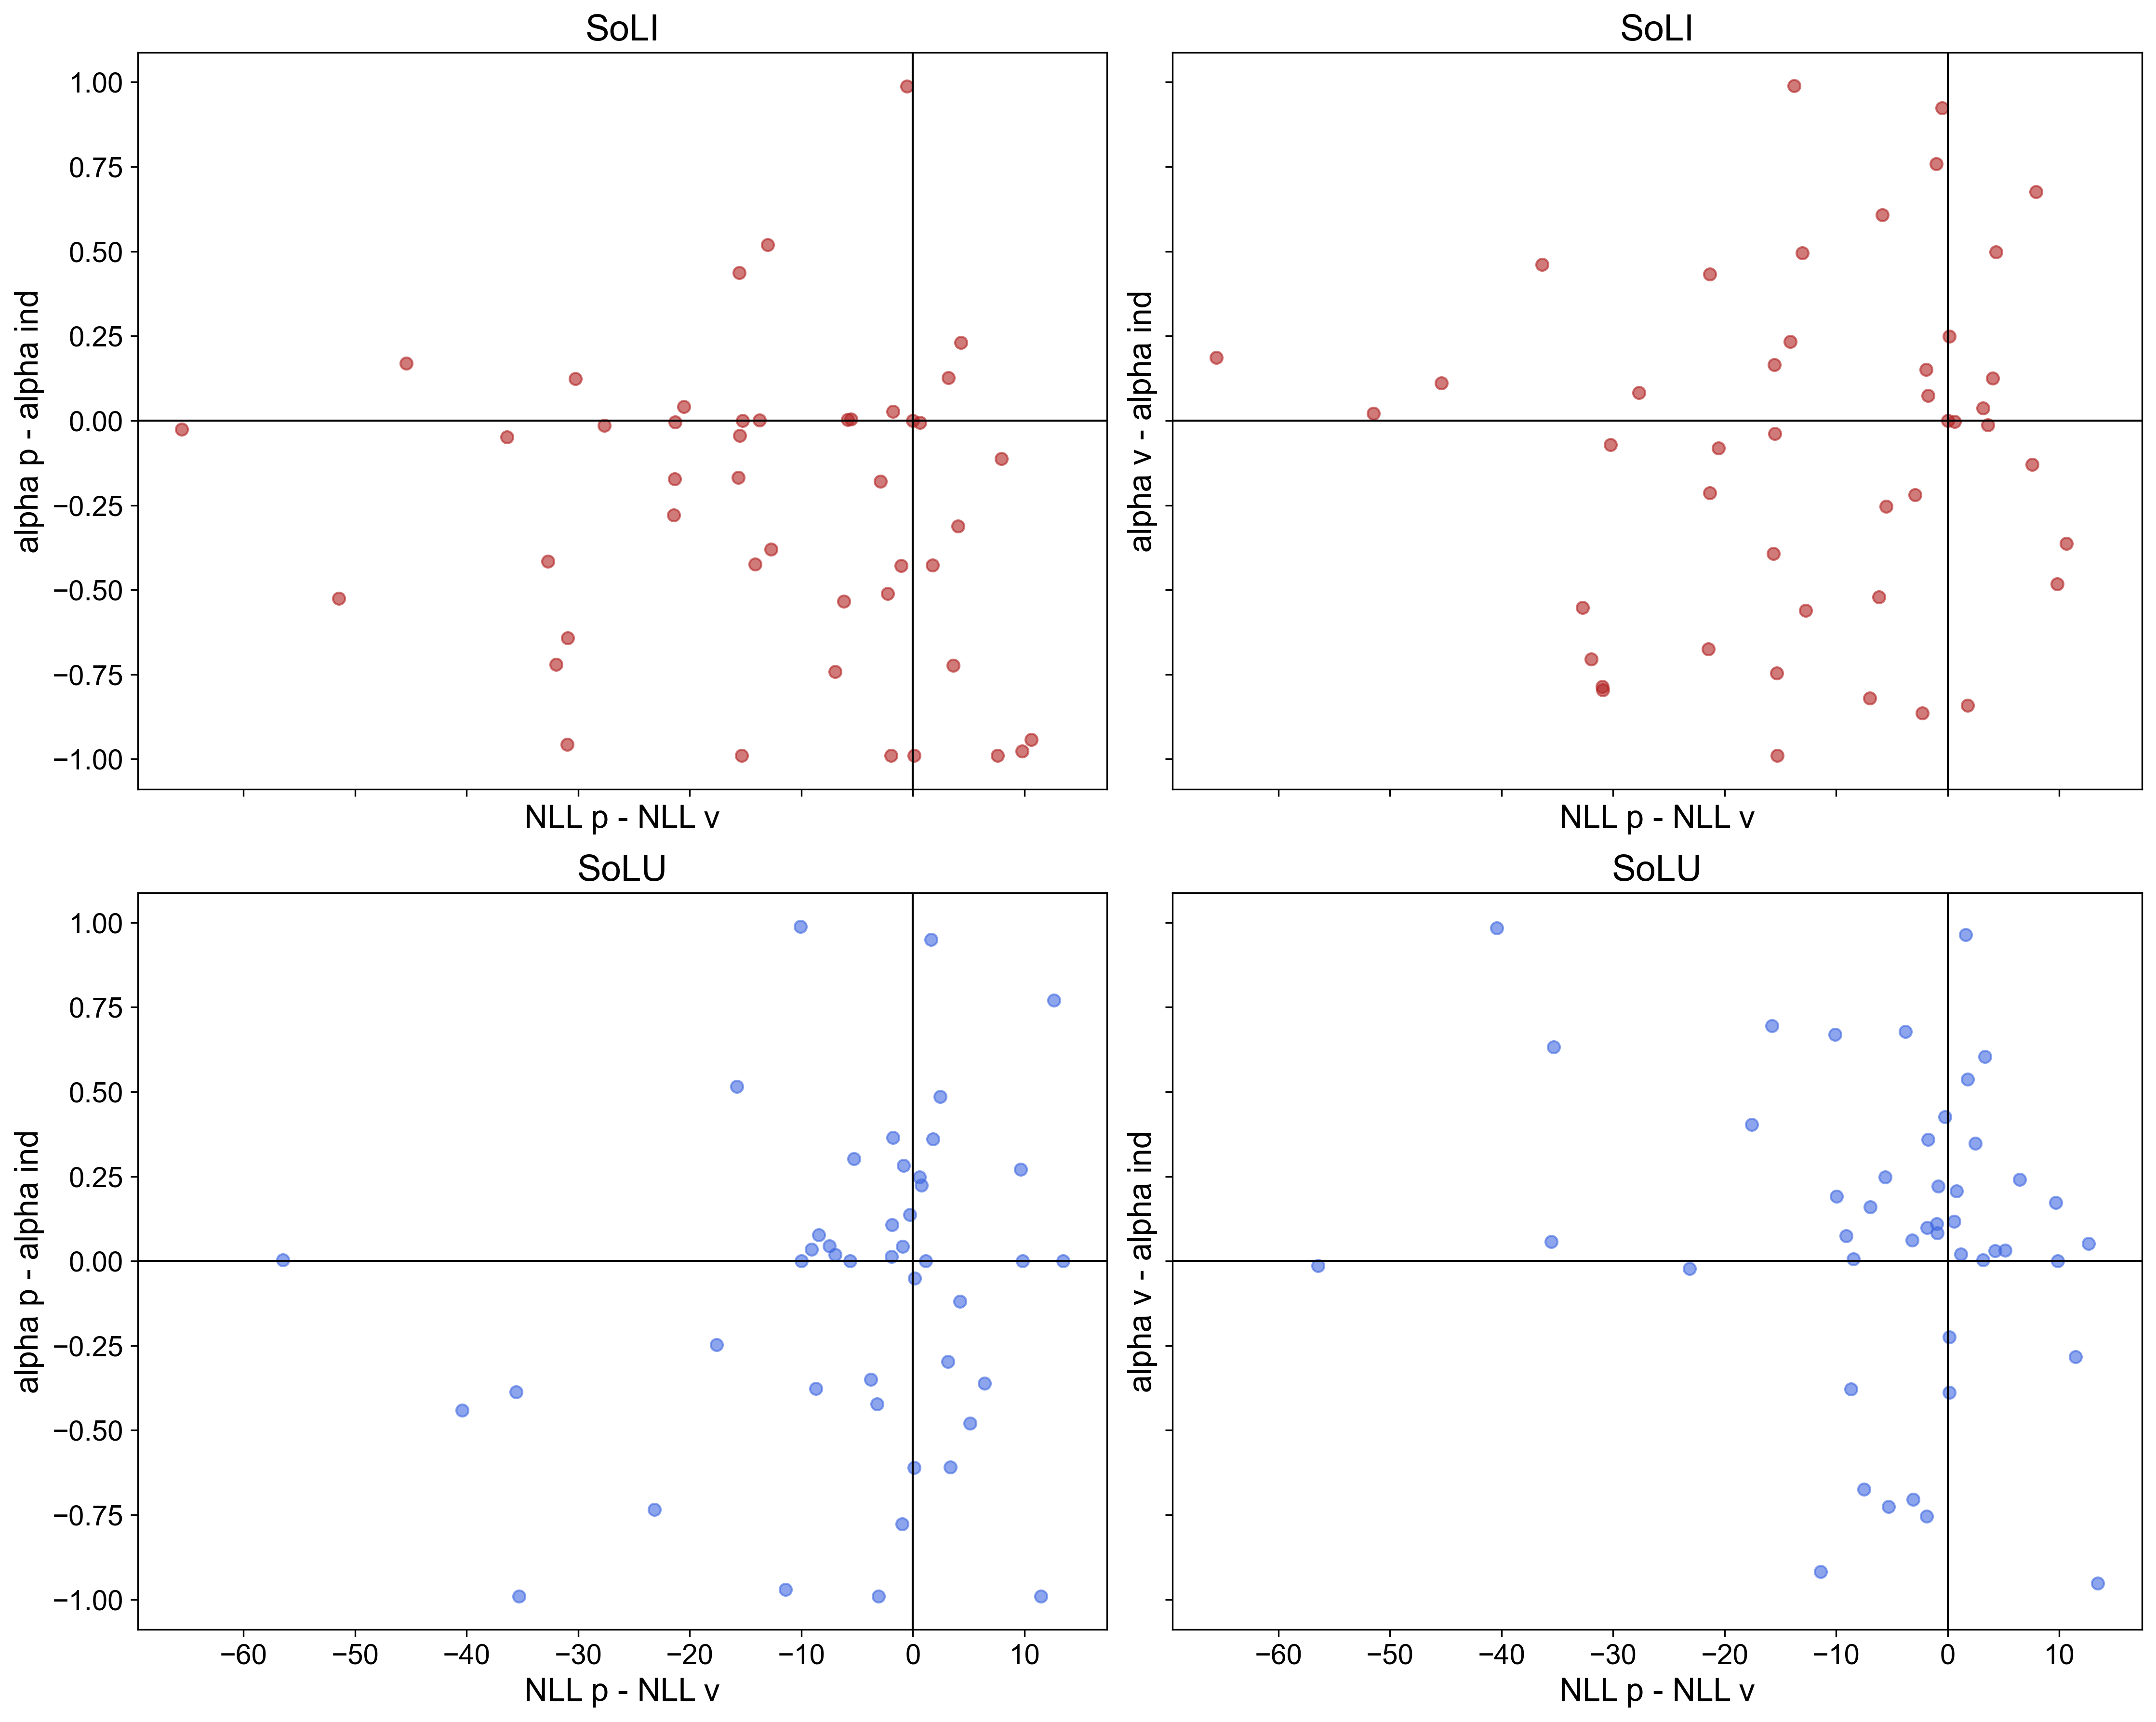

In [60]:
fig, axs = plt.subplots(2, 2, figsize=(15, 12), sharex=True, sharey=True)

label_fs = 16   # axis labels
title_fs = 18   # subplot titles
tick_fs = 14    # tick labels

# top-left (firebrick)
axs[0, 0].scatter(soli_sorted_diff_nll, soli_pi_diff_alpha,
                  color='firebrick', alpha=0.6)
axs[0, 0].set_xlabel('NLL p - NLL v', fontsize=label_fs)
axs[0, 0].set_ylabel('alpha p - alpha ind', fontsize=label_fs)
axs[0, 0].axhline(0, color='black', linewidth=1)
axs[0, 0].axvline(0, color='black', linewidth=1)
axs[0, 0].set_title('SoLI', fontsize=title_fs)

# top-right (firebrick)
axs[0, 1].scatter(soli_sorted_diff_nll, soli_vi_diff_alpha,
                  color='firebrick', alpha=0.6)
axs[0, 1].set_xlabel('NLL p - NLL v', fontsize=label_fs)
axs[0, 1].set_ylabel('alpha v - alpha ind', fontsize=label_fs)
axs[0, 1].axhline(0, color='black', linewidth=1)
axs[0, 1].axvline(0, color='black', linewidth=1)
axs[0, 1].set_title('SoLI', fontsize=title_fs)

# bottom-left (royalblue)
axs[1, 0].scatter(solu_sorted_diff_nll, solu_pi_diff_alpha,
                  color='royalblue', alpha=0.6)
axs[1, 0].set_xlabel('NLL p - NLL v', fontsize=label_fs)
axs[1, 0].set_ylabel('alpha p - alpha ind', fontsize=label_fs)
axs[1, 0].axhline(0, color='black', linewidth=1)
axs[1, 0].axvline(0, color='black', linewidth=1)
axs[1, 0].set_title('SoLU', fontsize=title_fs)

# bottom-right (royalblue)
axs[1, 1].scatter(solu_sorted_diff_nll, solu_vi_diff_alpha,
                  color='royalblue', alpha=0.6)
axs[1, 1].set_xlabel('NLL p - NLL v', fontsize=label_fs)
axs[1, 1].set_ylabel('alpha v - alpha ind', fontsize=label_fs)
axs[1, 1].axhline(0, color='black', linewidth=1)
axs[1, 1].axvline(0, color='black', linewidth=1)
axs[1, 1].set_title('SoLU', fontsize=title_fs)

# shared styling
for ax_row in axs:
    for ax in ax_row:
        ax.spines['top'].set_visible(True)
        ax.spines['right'].set_visible(True)
        ax.spines['left'].set_visible(True)
        ax.spines['bottom'].set_visible(True)
        ax.tick_params(axis='both', which='major', labelsize=tick_fs)

plt.tight_layout()


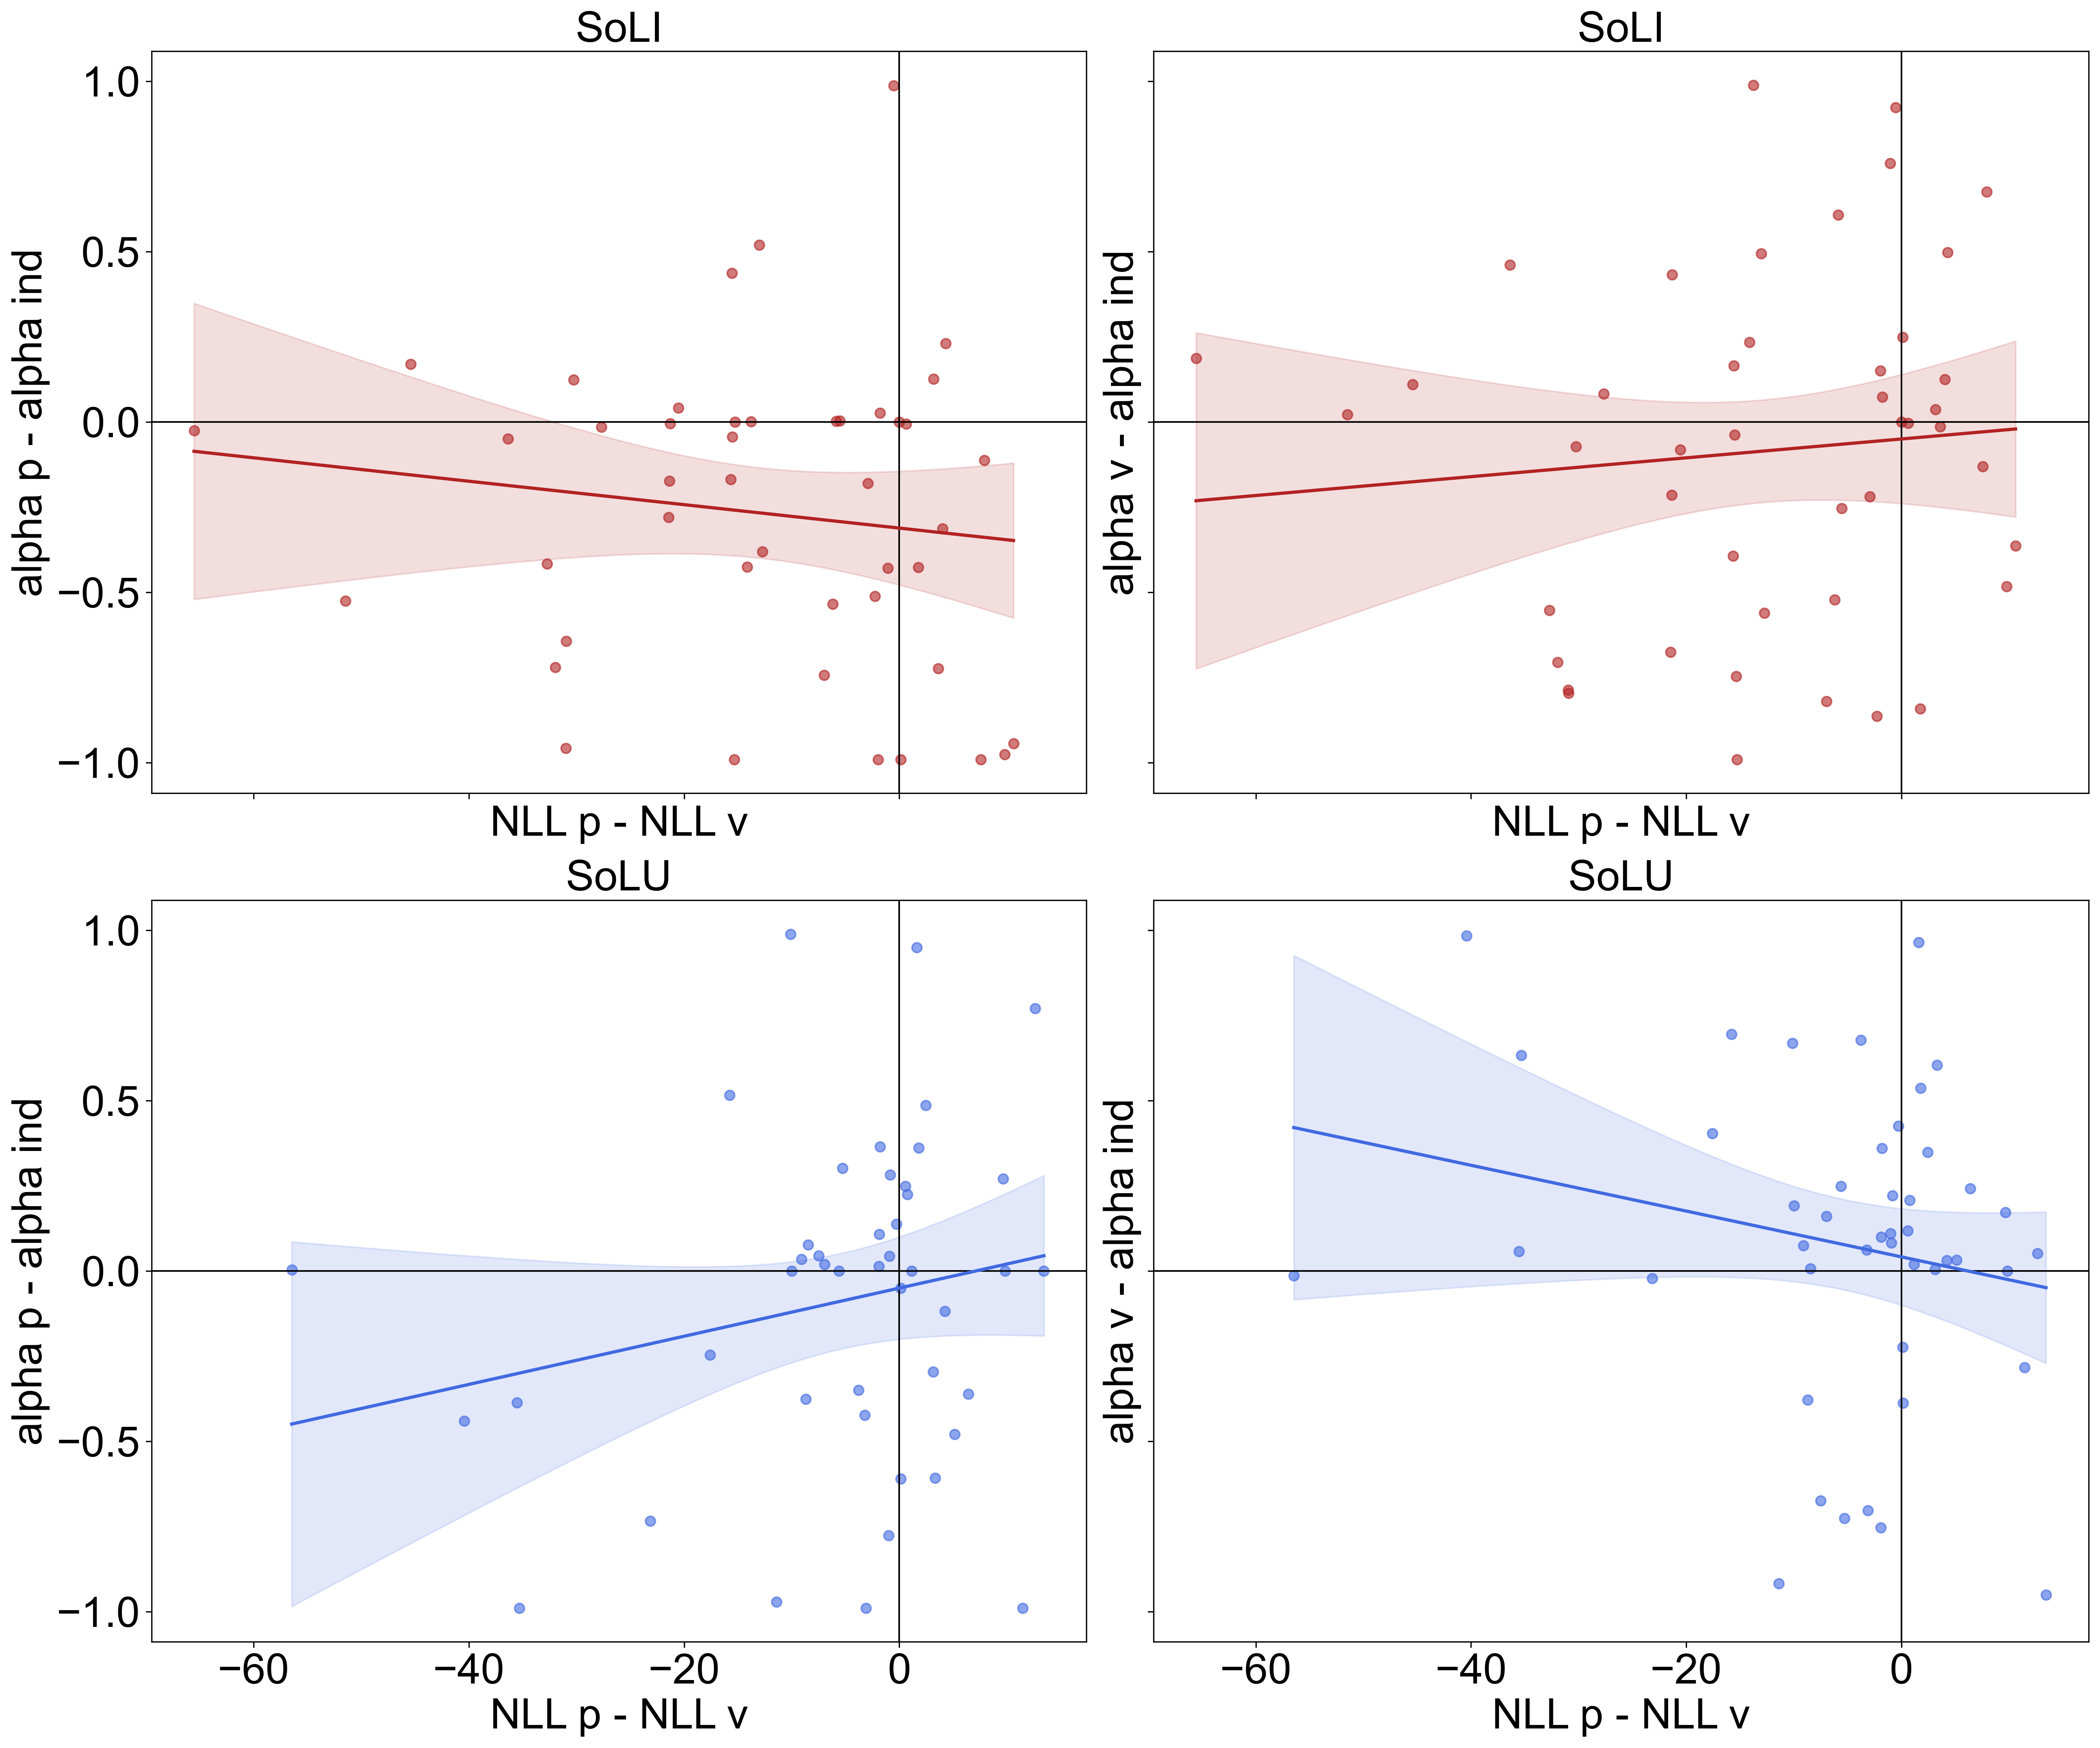

In [66]:
import numpy as np
import matplotlib.pyplot as plt

def add_regression_with_ci(ax, x, y, line_color, ci_alpha=0.15):
    x = np.asarray(x)
    y = np.asarray(y)

    # remove NaNs if any
    mask = ~np.isnan(x) & ~np.isnan(y)
    x = x[mask]
    y = y[mask]

    n = len(x)
    if n < 3:
        return  # not enough points to fit

    # linear regression (least squares)
    x_mean = x.mean()
    y_mean = y.mean()
    Sxx = np.sum((x - x_mean)**2)
    Sxy = np.sum((x - x_mean) * (y - y_mean))
    b1 = Sxy / Sxx
    b0 = y_mean - b1 * x_mean

    # x grid for plotting
    x_fit = np.linspace(x.min(), x.max(), 200)
    y_fit = b0 + b1 * x_fit

    # standard error of estimate
    y_pred = b0 + b1 * x
    s_err = np.sqrt(np.sum((y - y_pred)**2) / (n - 2))

    # 95% CI for mean prediction
    # t ~ 1.96 for large n
    t_val = 1.96
    ci = t_val * s_err * np.sqrt(1/n + (x_fit - x_mean)**2 / Sxx)

    ax.plot(x_fit, y_fit, color=line_color, linewidth=2)
    ax.fill_between(x_fit, y_fit - ci, y_fit + ci,
                    color=line_color, alpha=ci_alpha)


fig, axs = plt.subplots(2, 2, figsize=(18, 15), sharex=True, sharey=True)

label_fs = 26   # axis labels
title_fs = 26   # subplot titles
tick_fs = 26    # tick labels

# top-left (firebrick)
axs[0, 0].scatter(soli_sorted_diff_nll, soli_pi_diff_alpha,
                  color='firebrick', alpha=0.6)
axs[0, 0].set_xlabel('NLL p - NLL v', fontsize=label_fs)
axs[0, 0].set_ylabel('alpha p - alpha ind', fontsize=label_fs)
axs[0, 0].axhline(0, color='black', linewidth=1)
axs[0, 0].axvline(0, color='black', linewidth=1)
axs[0, 0].set_title('SoLI', fontsize=title_fs)
add_regression_with_ci(axs[0, 0],
                       soli_sorted_diff_nll,
                       soli_pi_diff_alpha,
                       line_color='firebrick')

# top-right (firebrick)
axs[0, 1].scatter(soli_sorted_diff_nll, soli_vi_diff_alpha,
                  color='firebrick', alpha=0.6)
axs[0, 1].set_xlabel('NLL p - NLL v', fontsize=label_fs)
axs[0, 1].set_ylabel('alpha v - alpha ind', fontsize=label_fs)
axs[0, 1].axhline(0, color='black', linewidth=1)
axs[0, 1].axvline(0, color='black', linewidth=1)
axs[0, 1].set_title('SoLI', fontsize=title_fs)
add_regression_with_ci(axs[0, 1],
                       soli_sorted_diff_nll,
                       soli_vi_diff_alpha,
                       line_color='firebrick')

# bottom-left (royalblue)
axs[1, 0].scatter(solu_sorted_diff_nll, solu_pi_diff_alpha,
                  color='royalblue', alpha=0.6)
axs[1, 0].set_xlabel('NLL p - NLL v', fontsize=label_fs)
axs[1, 0].set_ylabel('alpha p - alpha ind', fontsize=label_fs)
axs[1, 0].axhline(0, color='black', linewidth=1)
axs[1, 0].axvline(0, color='black', linewidth=1)
axs[1, 0].set_title('SoLU', fontsize=title_fs)
add_regression_with_ci(axs[1, 0],
                       solu_sorted_diff_nll,
                       solu_pi_diff_alpha,
                       line_color='royalblue')

# bottom-right (royalblue)
axs[1, 1].scatter(solu_sorted_diff_nll, solu_vi_diff_alpha,
                  color='royalblue', alpha=0.6)
axs[1, 1].set_xlabel('NLL p - NLL v', fontsize=label_fs)
axs[1, 1].set_ylabel('alpha v - alpha ind', fontsize=label_fs)
axs[1, 1].axhline(0, color='black', linewidth=1)
axs[1, 1].axvline(0, color='black', linewidth=1)
axs[1, 1].set_title('SoLU', fontsize=title_fs)
add_regression_with_ci(axs[1, 1],
                       solu_sorted_diff_nll,
                       solu_vi_diff_alpha,
                       line_color='royalblue')

# shared styling
for ax_row in axs:
    for ax in ax_row:
        ax.spines['top'].set_visible(True)
        ax.spines['right'].set_visible(True)
        ax.spines['left'].set_visible(True)
        ax.spines['bottom'].set_visible(True)
        ax.tick_params(axis='both', which='major', labelsize=tick_fs)

plt.tight_layout()
fig.savefig('D:/University/University of Tehran/MSc/Thesis/paper draft/main/paper draft/Figures/RLdifffinal.svg',  bbox_inches='tight', pad_inches=0.02)

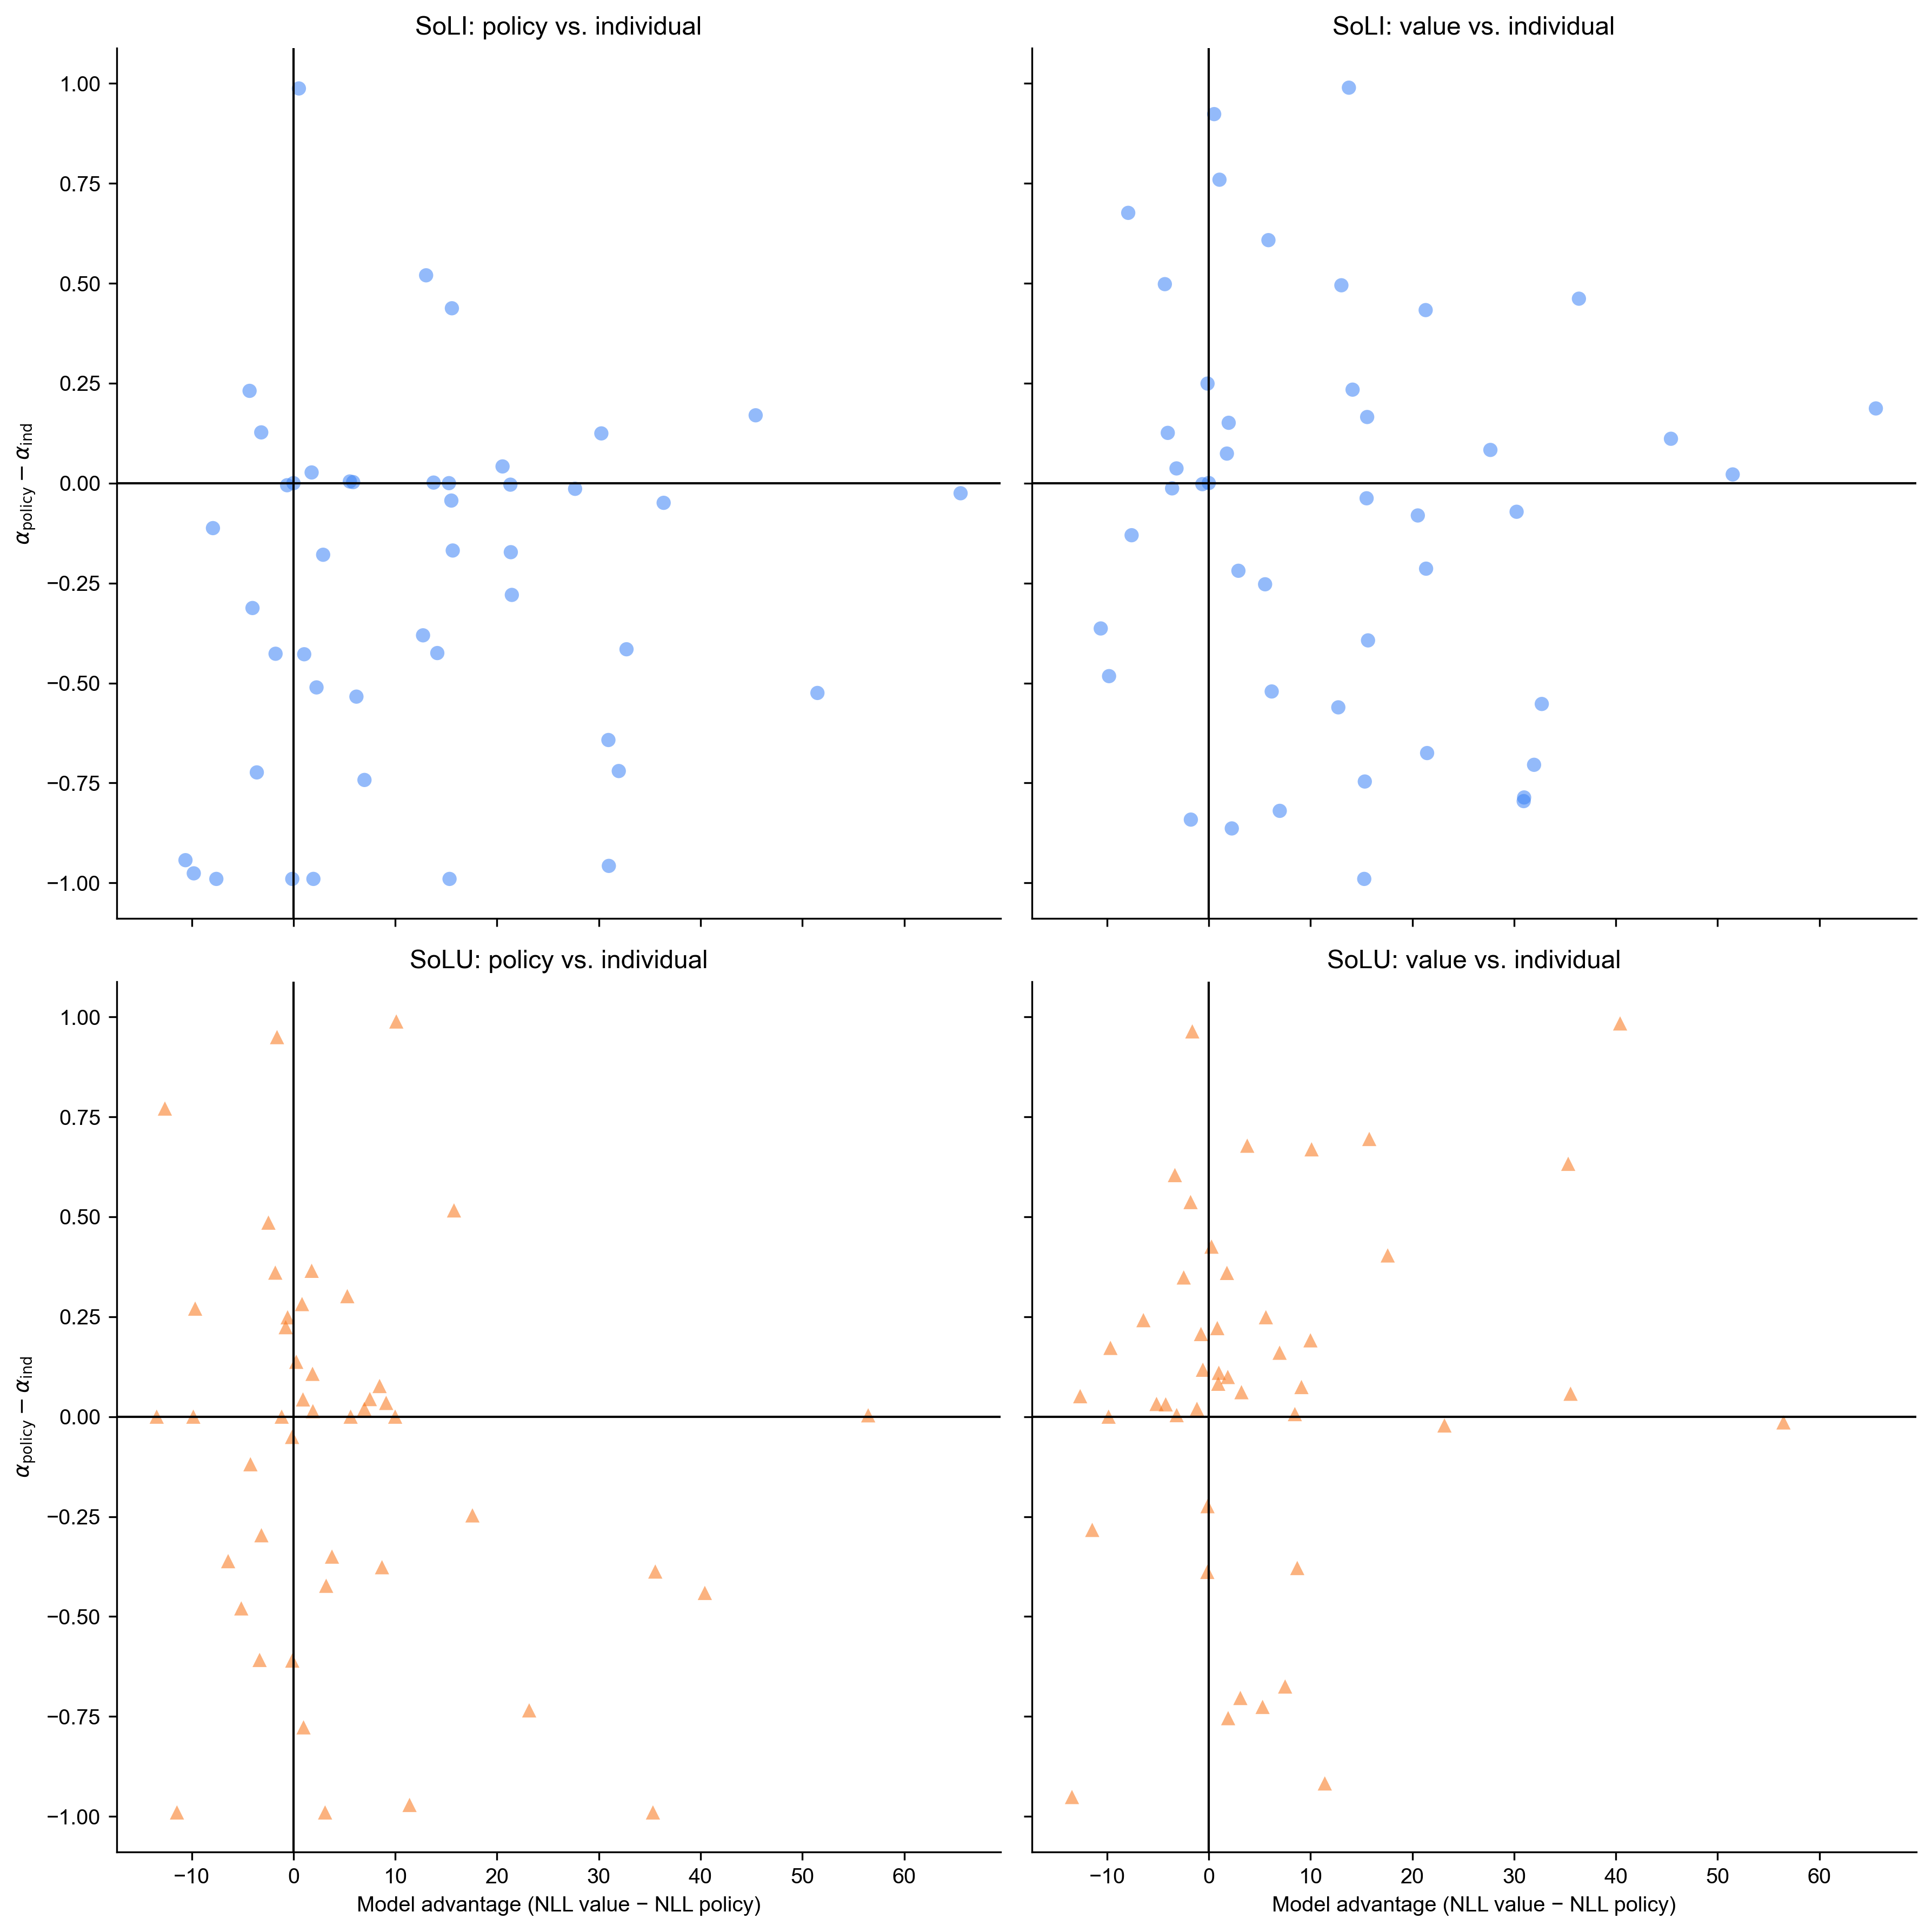

In [62]:
import numpy as np
import matplotlib.pyplot as plt

fig, axs = plt.subplots(2, 2, figsize=(12, 12), sharex=True, sharey=True)

# make "positive = policy better"
# original was (NLL_p - NLL_v); flip sign:
soli_policy_adv = -1 * soli_sorted_diff_nll      # SoLI
solu_policy_adv = -1 * solu_sorted_diff_nll      # SoLU

# SoLI, policy α – individual α
axs[0, 0].scatter(
    soli_policy_adv,
    soli_pi_diff_alpha,
    s=40,
    alpha=0.55,
    color='#3b82f6',   # blue
    edgecolor='none',
    marker='o'
)
axs[0, 0].axhline(0, color='black', linewidth=1)
axs[0, 0].axvline(0, color='black', linewidth=1)
axs[0, 0].set_ylabel(r'$\alpha_{\mathrm{policy}} - \alpha_{\mathrm{ind}}$')
axs[0, 0].set_title('SoLI: policy vs. individual')

# SoLI, value α – individual α
axs[0, 1].scatter(
    soli_policy_adv,
    soli_vi_diff_alpha,
    s=40,
    alpha=0.55,
    color='#3b82f6',
    edgecolor='none',
    marker='o'
)
axs[0, 1].axhline(0, color='black', linewidth=1)
axs[0, 1].axvline(0, color='black', linewidth=1)
axs[0, 1].set_title('SoLI: value vs. individual')

# SoLU, policy α – individual α
axs[1, 0].scatter(
    solu_policy_adv,
    solu_pi_diff_alpha,
    s=40,
    alpha=0.55,
    color='#f97316',   # orange
    edgecolor='none',
    marker='^'
)
axs[1, 0].axhline(0, color='black', linewidth=1)
axs[1, 0].axvline(0, color='black', linewidth=1)
axs[1, 0].set_ylabel(r'$\alpha_{\mathrm{policy}} - \alpha_{\mathrm{ind}}$')
axs[1, 0].set_title('SoLU: policy vs. individual')

# SoLU, value α – individual α
axs[1, 1].scatter(
    solu_policy_adv,
    solu_vi_diff_alpha,
    s=40,
    alpha=0.55,
    color='#f97316',
    edgecolor='none',
    marker='^'
)
axs[1, 1].axhline(0, color='black', linewidth=1)
axs[1, 1].axvline(0, color='black', linewidth=1)
axs[1, 1].set_title('SoLU: value vs. individual')

# shared x-label for bottom row
for ax in axs[1, :]:
    ax.set_xlabel('Model advantage (NLL value − NLL policy)')

plt.tight_layout()

